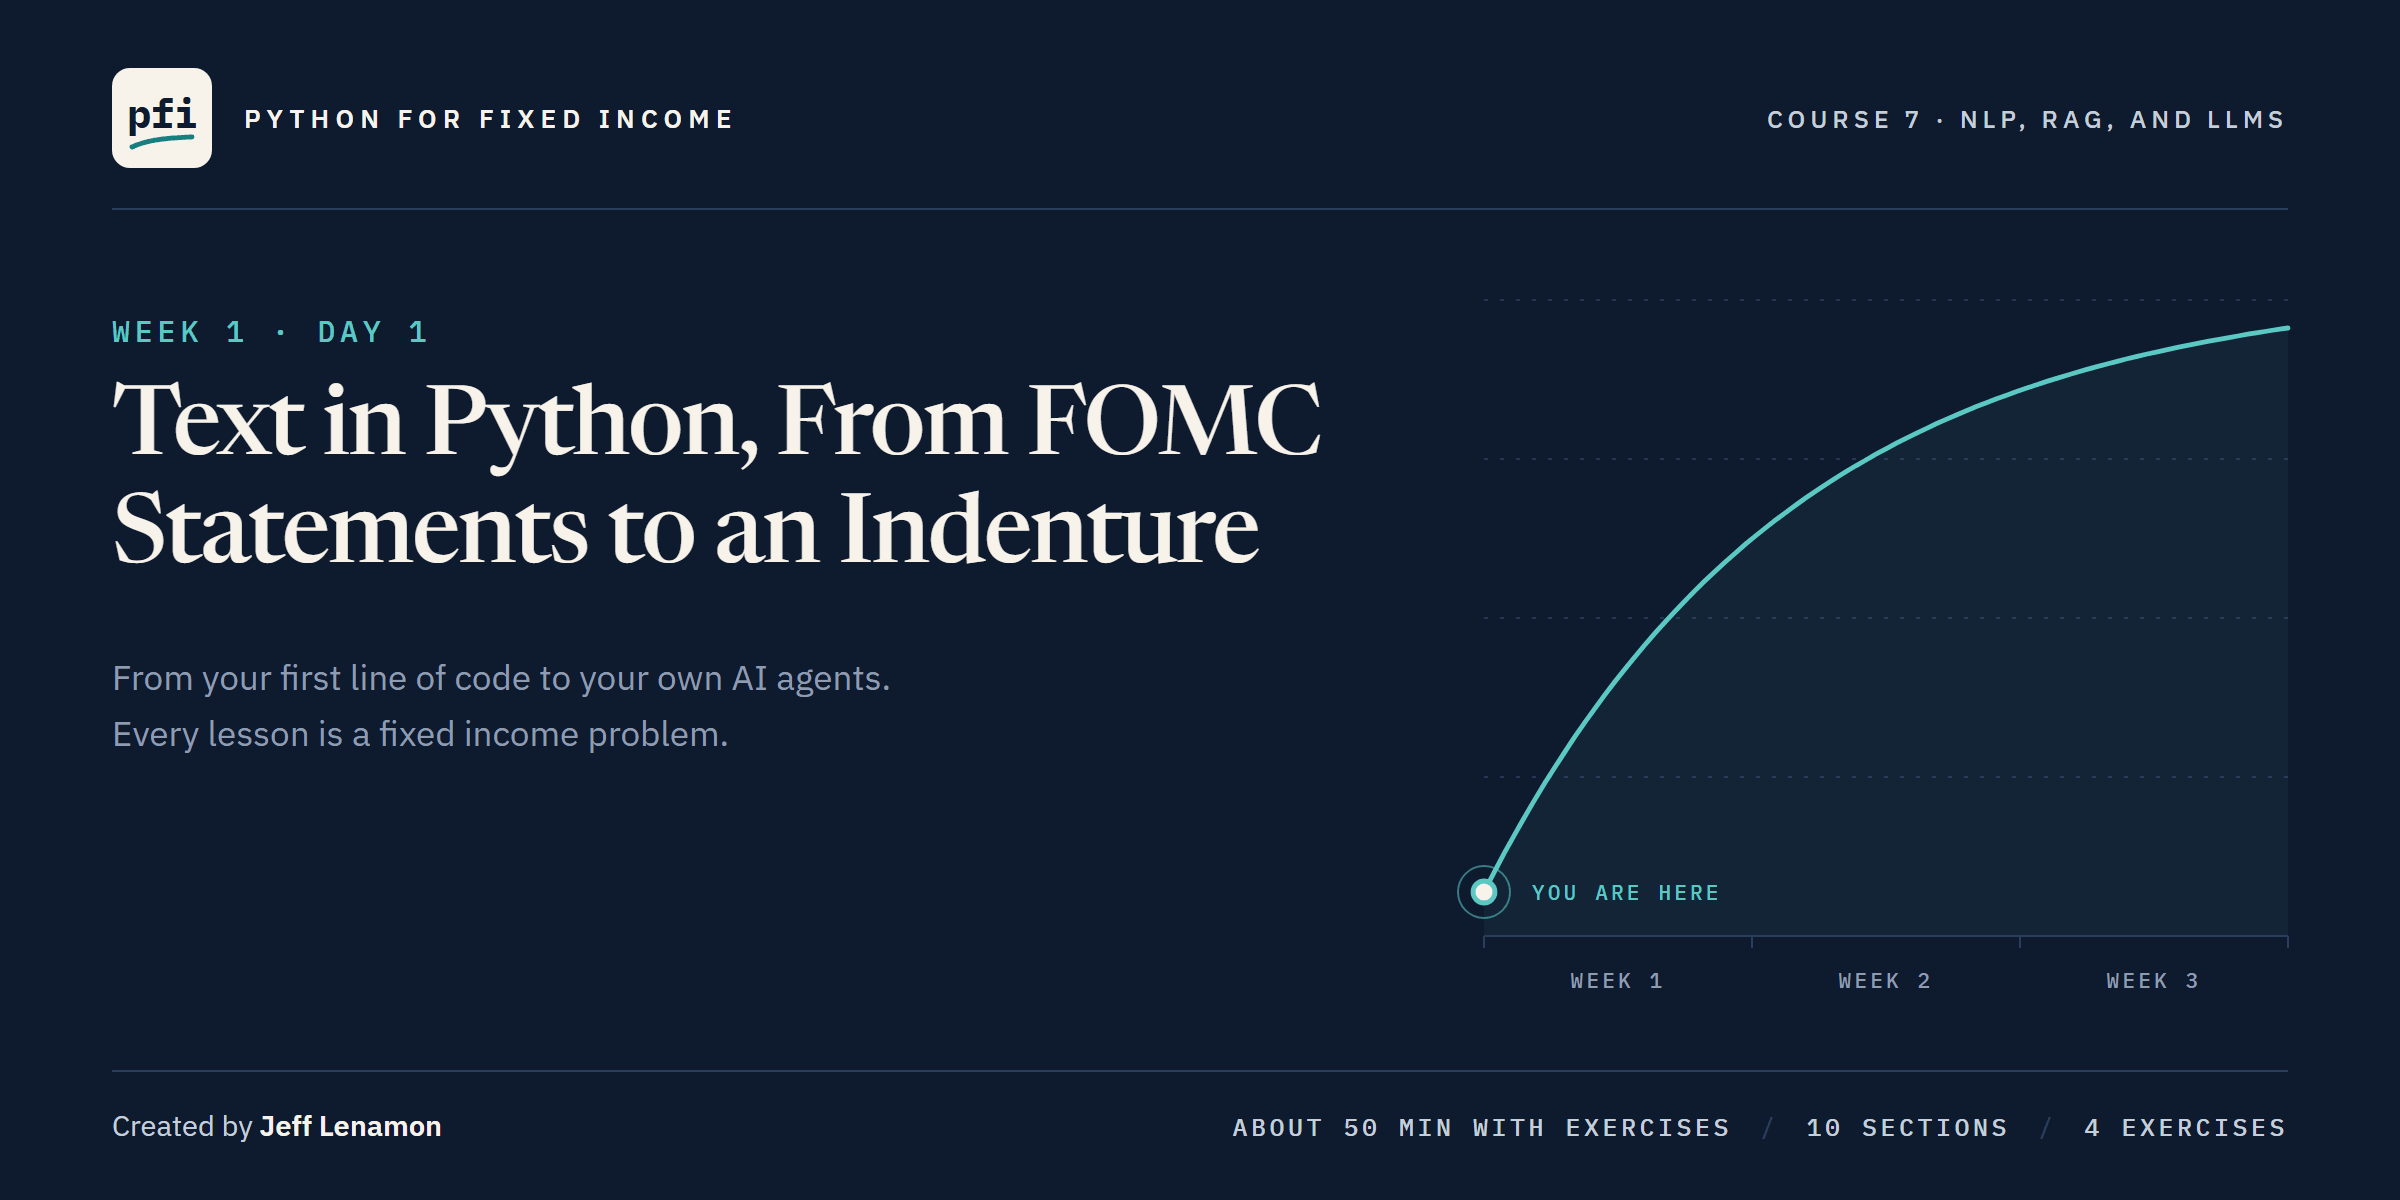

# Text in Python, From FOMC Statements to an Indenture

Week 1, Day 1. Make text into data: plain characters, a rate read from every statement, tokens counted, and an indenture mapped by its sections and defined terms.

**Data:** `course7_fomc_statements.csv`, 226 FOMC post-meeting statements, 2000-02-02 to 2026-09-16: **real**, Board of Governors of the Federal Reserve System, public domain (federalreserve.gov).

**Data:** `course7_indentures/boyd_2021.txt`: Boyd Gaming Corporation, Indenture dated as of June 8, 2021, 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495: **real**, a public record on sec.gov, quoted for descriptive extraction only.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course07_nlp_and_llms/week1/day1/01_text_in_python_fomc_statements_and_an_indenture.ipynb)

# Problem Statement

## Business Context

A credit desk keeps two kinds of text it never puts in a table: the FOMC's post-meeting statements and the indentures of the bonds it holds.
It wants the rate each statement states as a column, word counts by date, and a map of one indenture's sections and defined terms for later notebooks to search.
Course 1 read 46 statements with patterns tuned by hand; today's file holds 226 statements from 2000 to 2026, beside one indenture of 63,595 words.
Both are real public documents, quoted for description only: a count is a count for a stated date, never a reading of policy and never a judgement of the issuer or its notes.
Today fits nothing, so nothing is split, and the indenture is never a training set.

## Objectives

Find characters that look alike and make them plain.
Pull the stated rate out of every statement with regular expressions and turn it into a number.
Split text into tokens and count them.
Find an indenture's sections from its headings and list the terms it defines.
Check every pattern against the whole document it runs on.

## Data Dictionary

`course7_fomc_statements.csv`, one row per statement:

1. `date`: the meeting's date, as text
2. `url`: the statement's page on federalreserve.gov
3. `scheduled`: True after a scheduled meeting, False after an unscheduled one
4. `text`: the statement as published, one paragraph per line

`course7_indentures/boyd_2021.txt`: the indenture as filed, made plain text with one paragraph per line by the course's tool (Day 9 writes that step).

Made in the notebook: `clean`, the rate columns `kind`, `low`, `high`, `low_percent` and `high_percent`, `token_list` and `tokens`, and two tables, `sections` and `terms`.

## Your Route Through Day 1

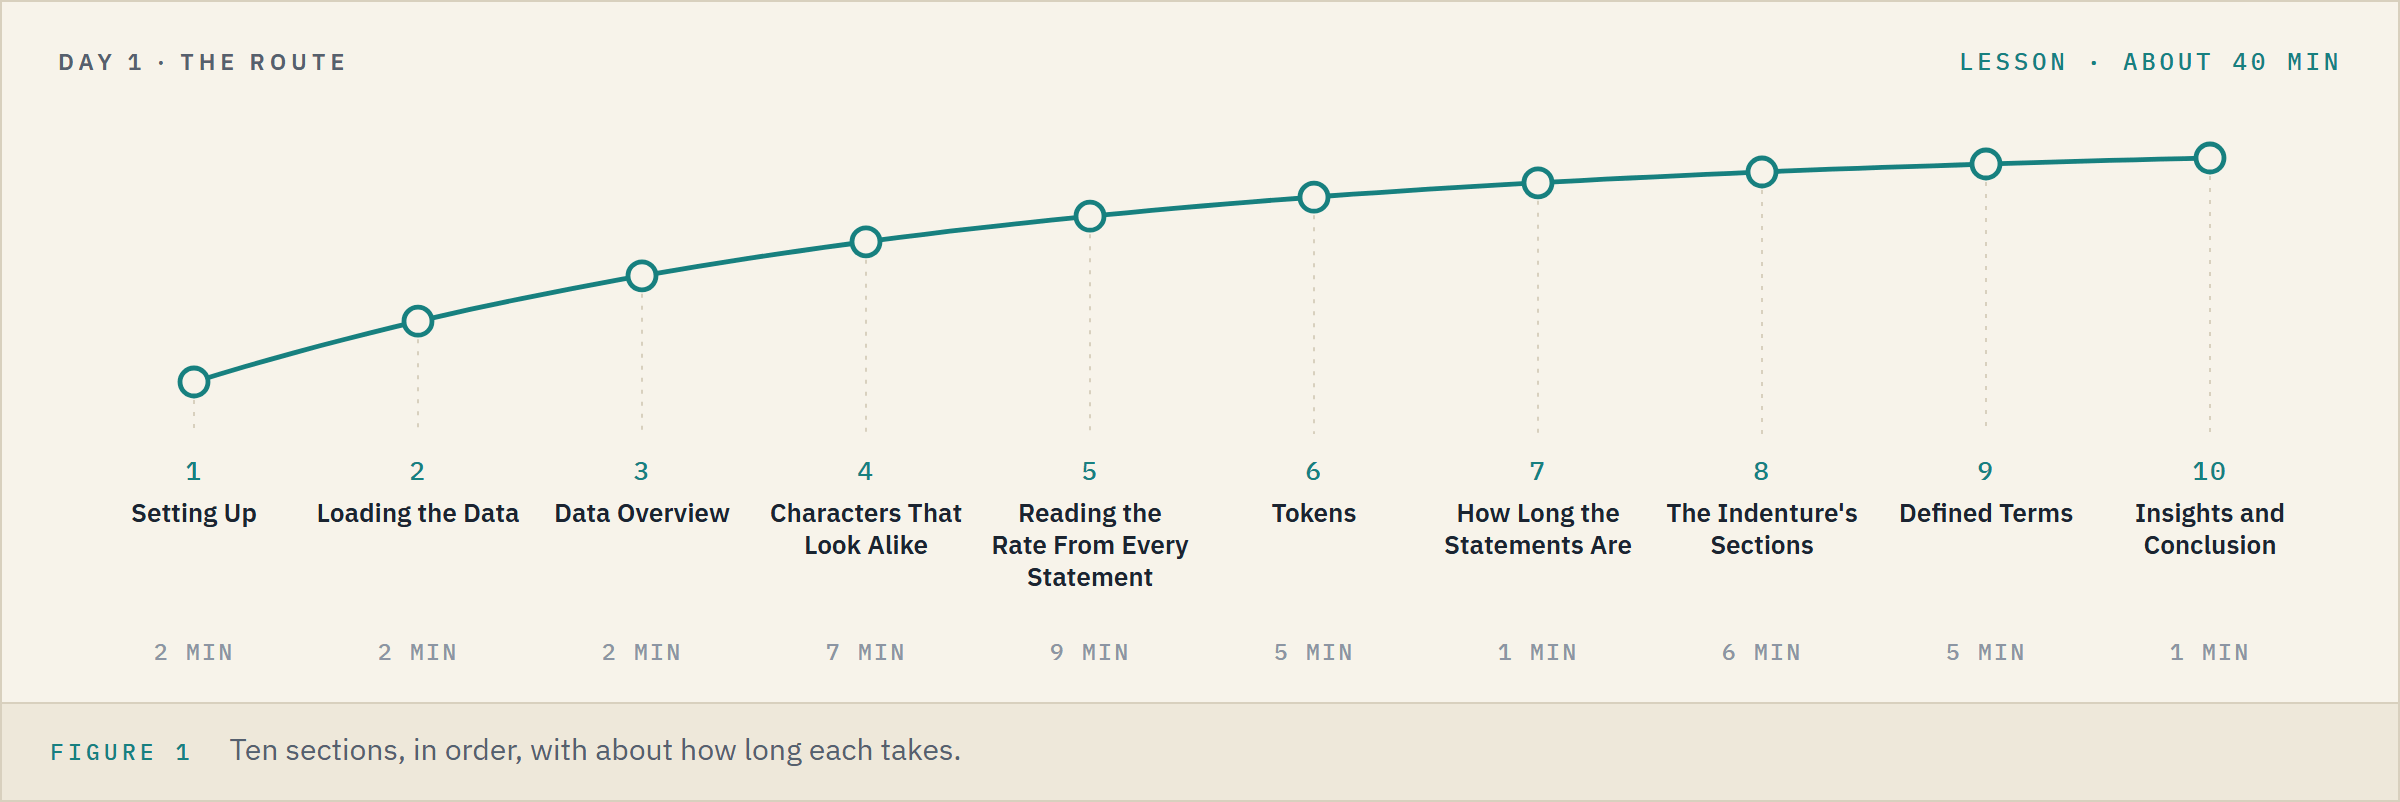

**Time.** About 40 minutes for the lesson, then about 12 for the four exercises.

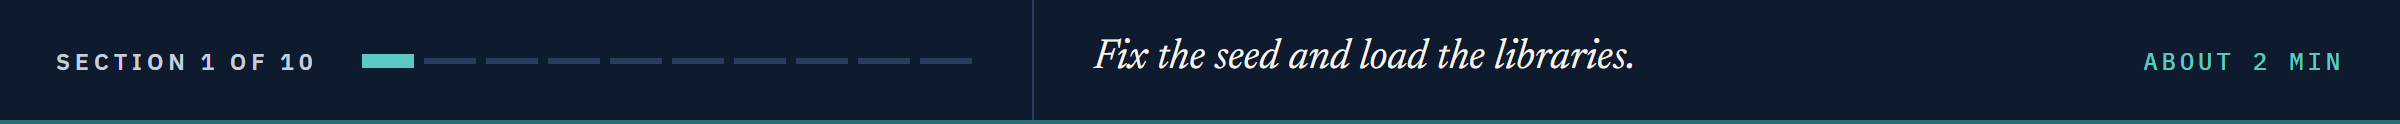

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# text: regular expressions, Unicode names and forms, and a counter
import re
import unicodedata
from collections import Counter

# data, charts and a dropdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# scikit-learn's list of common English words
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# one look for every chart
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)

## Reading Files That Are Not Tables

`pd.read_csv` reads a table from the repo or straight from GitHub, but a text file needs a path on this machine.
`data_file(name)` returns the repo's path on your machine; in Colab it downloads the file once and returns the copy's name.

In [3]:
# the course's text, array, PDF and JSON files: from the repo's data folder, or downloaded once from GitHub in Colab
from urllib.request import urlretrieve


def data_file(name):
    """The path of a course data file on this machine (in Colab, a copy fetched from GitHub the first time)."""
    if not DATA.startswith("https://"):
        return DATA + name
    local = Path(name).name
    if not Path(local).exists():
        urlretrieve(DATA + name, local)
    return local

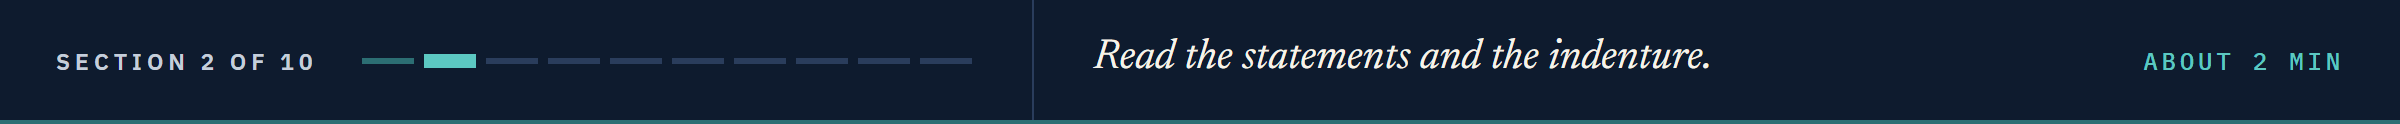

# Loading the Data

## The Statements

In [4]:
# every post-meeting statement in the file, one row each
statements = pd.read_csv(DATA + "course7_fomc_statements.csv")
statements.shape

(226, 4)

## The Indenture

`Path(...).read_text(encoding="utf-8")` reads a whole text file into one string.

In [5]:
# the Boyd indenture as one string of characters
boyd_raw = Path(data_file("course7_indentures/boyd_2021.txt")).read_text(encoding="utf-8")
len(boyd_raw)

392021

226 statements in 4 columns, and one indenture of 392,021 characters.

> STORY: Why the file starts in 2000.
> The Board's page of historical materials says: "The FOMC first announced the outcome of a meeting in February 1994."
> And: "In January 2000, the Committee announced that it would issue a statement following each regularly scheduled meeting, regardless of whether there had been a change in monetary policy."
> The Board's FAQ page dates the practice earlier: "Since May 1999, the FOMC has issued statements following each meeting regardless of whether it changed policy."
> The two pages give different dates; the course's file starts with the Board's yearly page for 2000, at 2000-02-02.
> Sources: Board of Governors of the Federal Reserve System, https://www.federalreserve.gov/monetarypolicy/fomc_historical.htm and https://www.federalreserve.gov/faqs/federal-open-market-committee-fomc-not-public.htm (both read 2026-11-18)

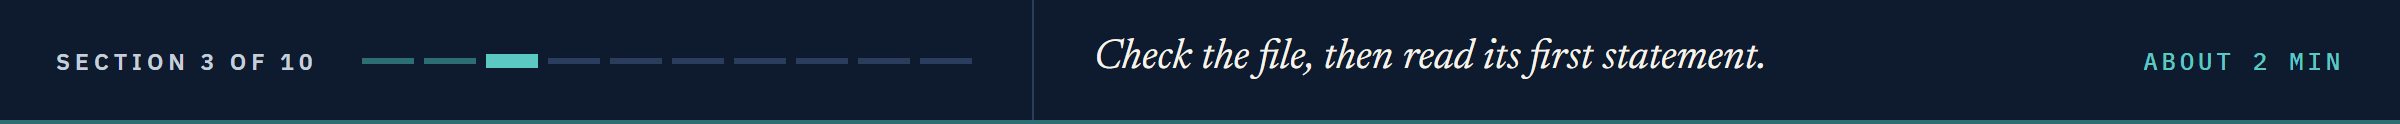

# Data Overview

## Checking the Dates, the Meetings and the Gaps

2000-02-02 to 2026-09-16 | {True: 213, False: 13}
{'2001': 3, '2007': 2, '2008': 3, '2010': 1, '2019': 1, '2020': 3}
0 0 0


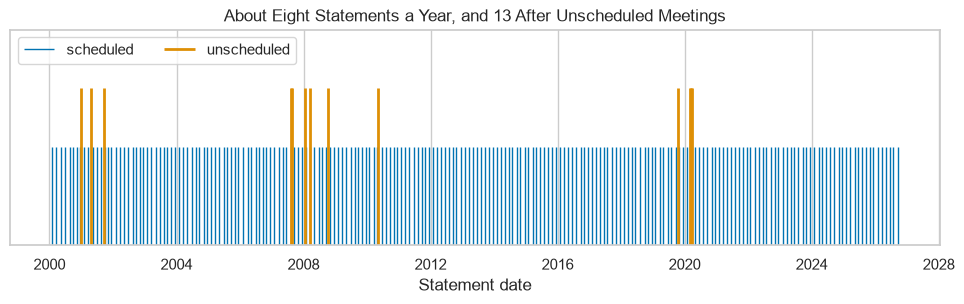

In [6]:
# the first and last dates, the statements after each kind of meeting, and the unscheduled ones by year
year = statements["date"].str[:4]
print(statements["date"].min(), "to", statements["date"].max(), "|", statements["scheduled"].value_counts().to_dict())
print(year[~statements["scheduled"]].value_counts().sort_index().to_dict())

# empty cells, repeated dates and repeated texts
print(statements.isna().sum().sum(), statements["date"].duplicated().sum(), statements["text"].duplicated().sum())

# every statement as a tick on a time line, the unscheduled ones taller and in orange
when = pd.to_datetime(statements["date"])
fig, ax = plt.subplots(figsize=(12, 2.8))
ax.vlines(when[statements["scheduled"]], 0, 1, color="C0", linewidth=1, label="scheduled")
ax.vlines(when[~statements["scheduled"]], 0, 1.6, color="C1", linewidth=2, label="unscheduled")
ax.set(yticks=[], ylim=(0, 2.2), xlabel="Statement date")
ax.legend(loc="upper left", ncols=2)
ax.set_title("About Eight Statements a Year, and 13 After Unscheduled Meetings")
plt.show()

213 statements follow scheduled meetings, about eight a year; the 13 unscheduled ones cluster in 2001, 2007 and 2008, and 2020.

Nothing is missing, and each date and each text appears once.

## The First Statement

Every excerpt in the course carries a **source line** naming where its text comes from.

In [7]:
# source text: quoted as published
# the line that names where a statement's text comes from
def statement_source(row):
    """Print the source line of one statement."""
    print(f"Source: FOMC post-meeting statement of {row['date']}, Board of Governors of the Federal Reserve System, {row['url']}")


# the first statement: its length in characters, then its first 300
row = statements.iloc[0]
print(len(row["text"]), "characters")
print(row["text"][:300])
statement_source(row)

1254 characters
The Federal Open Market Committee voted today to raise its target for the federal funds rate by 25 basis points to 5-3/4 percent. In a related action, the Board of Governors approved a 25 basis point increase in the discount rate to 5-1/4 percent.
The Committee remains concerned that over time incre
Source: FOMC post-meeting statement of 2000-02-02, Board of Governors of the Federal Reserve System, https://www.federalreserve.gov/boarddocs/press/general/2000/20000202/


`len`, slicing and `.split()` are Course 1's, and so is the trap in `.count("rate")`, which also counts the letters inside "rates".

**The file is complete; before any count, we check what its characters are.**

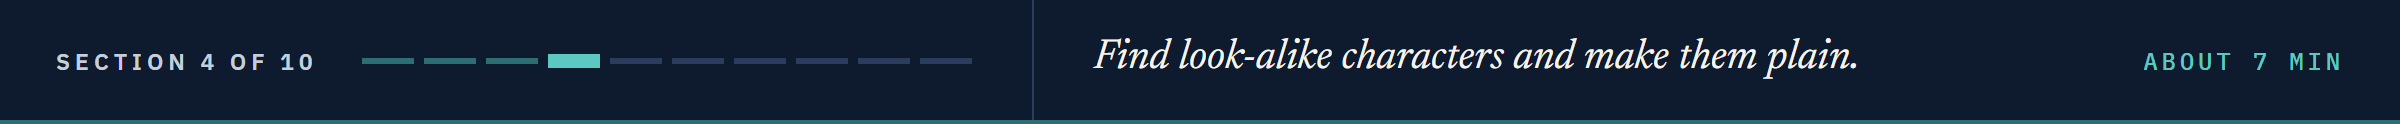

# Characters That Look Alike

**Predict 1**

Course 1 met the non-breaking hyphen in its 46 statements.

Q. How many distinct characters outside ASCII do the 226 statements hold? Write down a number.

## Every Character Outside ASCII

Every character is stored as a number, its **code point**, and `ord(ch)` returns it.
**ASCII**, the keyboard's characters, runs from 0 to 127.
`unicodedata.name(ch)` returns a character's Unicode name, and `:04X` writes a number as four hexadecimal digits, as in "U+2011".

In [8]:
# every character above 127 in all 226 statements, counted
outside = Counter(ch for text in statements["text"] for ch in text if ord(ch) > 127)

# each by code point and name, never printed as itself (regex=False: the character is searched as itself, not as a pattern)
found = []
for ch, times in outside.most_common():
    holds = statements["text"].str.contains(ch, regex=False)
    dates = statements["date"][holds].min() + " to " + statements["date"][holds].max()
    found.append({"code point": f"U+{ord(ch):04X}", "name": unicodedata.name(ch), "times": times, "statements": holds.sum(), "dates": dates})
pd.DataFrame(found)

,code point,name,times,statements,dates
0,U+2011,NON-BREAKING HYPHEN,50,34,2015-07-29 to 2026-04-29
1,U+2019,RIGHT SINGLE QUOTATION MARK,25,19,2007-09-18 to 2022-05-04
2,U+2013,EN DASH,3,3,2026-06-17 to 2026-09-16
3,U+2014,EM DASH,2,1,2020-03-15 to 2020-03-15


Four characters: the non-breaking hyphen is the most common, then the right single quote.

The en dash sits in three 2026 statements, in each one's vote line, and the em dash twice in 2020-03-15.

## Two Hyphens That Look the Same

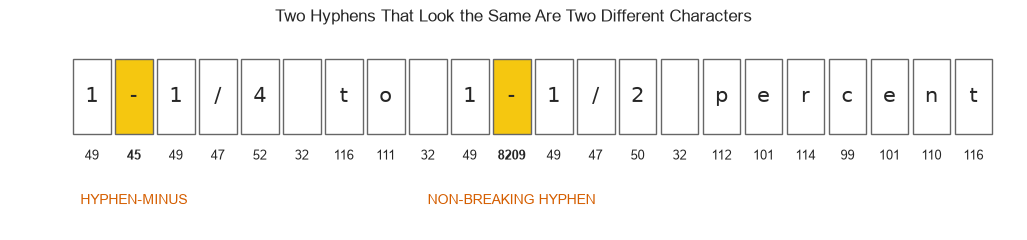

In [9]:
# the range in the statement of 2017-12-13 as published: one box per character, its code point under it
published = statements.loc[statements["date"] == "2017-12-13", "text"].iloc[0]
piece = re.search(r"1-1/4 to 1.1/2 percent", published).group(0)
fig, ax = plt.subplots(figsize=(13, 2.6))
for i, ch in enumerate(piece):
    ax.add_patch(plt.Rectangle((i, 0), 0.9, 1, facecolor="#F5C710" if i in (1, 10) else "white", edgecolor="0.4"))
    ax.text(i + 0.45, 0.5, ch, ha="center", va="center", fontsize=15, family="DejaVu Sans")
    ax.text(i + 0.45, -0.35, ord(ch), ha="center", fontsize=9, weight="bold" if i in (1, 10) else "normal")
    if i in (1, 10):
        ax.text(i + 0.45, -0.95, unicodedata.name(ch), ha="center", fontsize=10, color="C3")
ax.set(xlim=(-1.5, len(piece) + 0.5), ylim=(-1.3, 1.4), title="Two Hyphens That Look the Same Are Two Different Characters")
ax.set_axis_off()
plt.show()

On screen both halves of the range read alike; to Python, 45 and 8209 are different characters.

## Which Years

8 statements in 2021


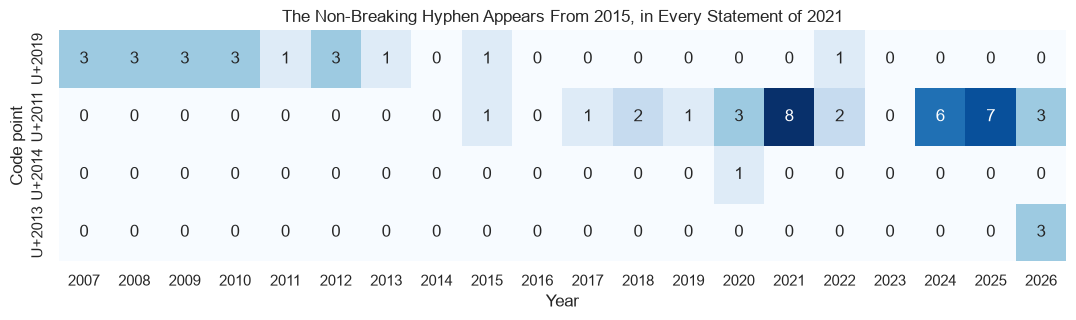

In [10]:
# for each look-alike, how many statements of each year hold it, from 2007; and the statements of 2021
holds = pd.DataFrame({f"U+{ord(ch):04X}": statements["text"].str.contains(ch, regex=False) for ch in outside})
by_year = holds.groupby(year).sum().loc["2007":].T
print((year == "2021").sum(), "statements in 2021")
plt.figure(figsize=(13, 3))
sns.heatmap(by_year, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("Year")
plt.ylabel("Code point")
plt.title("The Non-Breaking Hyphen Appears From 2015, in Every Statement of 2021")
plt.show()

The non-breaking hyphen appears from 2015, and in all 8 statements of 2021.

## One Phrase, Two Spellings

`chr(0x2011)` is the character whose code point is 2011 in hexadecimal (`0x` marks a hexadecimal number), so the source stays plain ASCII.

In [11]:
# "longer-term" typed with the keyboard's hyphen, typed with U+2011, and either
keyboard = statements["text"].str.contains("longer-term")
nonbreaking = statements["text"].str.contains("longer" + chr(0x2011) + "term")
print("keyboard hyphen:", keyboard.sum(), "| U+2011:", nonbreaking.sum(), "| either:", (keyboard | nonbreaking).sum())

keyboard hyphen: 102 | U+2011: 7 | either: 109


A search typed on a keyboard misses 7 of the 109 statements that write "longer-term".

## A Map of Look-Alikes

`str.maketrans(mapping)` builds a table from a dictionary of characters, and `text.translate(table)` swaps every character the table names.

In [12]:
# nine look-alikes and the keyboard character each becomes: the course's map, used on every text
CHARACTER_MAP = {chr(0x00A0): " ", chr(0x2010): "-", chr(0x2011): "-", chr(0x2013): "-", chr(0x2014): "-",
                 chr(0x2018): "'", chr(0x2019): "'", chr(0x201C): '"', chr(0x201D): '"'}
for ch, plain in CHARACTER_MAP.items():
    print(f"U+{ord(ch):04X}", unicodedata.name(ch), "->", repr(plain))

# the range of 2017-12-13 through the map: the code points of its two hyphens before and after
plain_piece = piece.translate(str.maketrans(CHARACTER_MAP))
print(ord(piece[1]), ord(piece[10]), "->", ord(plain_piece[1]), ord(plain_piece[10]), "|", plain_piece)

U+00A0 NO-BREAK SPACE -> ' '
U+2010 HYPHEN -> '-'
U+2011 NON-BREAKING HYPHEN -> '-'
U+2013 EN DASH -> '-'
U+2014 EM DASH -> '-'
U+2018 LEFT SINGLE QUOTATION MARK -> "'"
U+2019 RIGHT SINGLE QUOTATION MARK -> "'"
U+201C LEFT DOUBLE QUOTATION MARK -> '"'
U+201D RIGHT DOUBLE QUOTATION MARK -> '"'
45 8209 -> 45 45 | 1-1/4 to 1-1/2 percent


## Unicode's Own Forms

`unicodedata.normalize(form, text)` is Unicode's own clean-up.
**NFC** joins a letter and its accent into one code point; **NFKC** also folds characters Unicode lists as compatible.

In [13]:
# how many statements each form changes
nfc = sum(unicodedata.normalize("NFC", text) != text for text in statements["text"])
nfkc = sum(unicodedata.normalize("NFKC", text) != text for text in statements["text"])
print("NFC changes", nfc, "statements | NFKC changes", nfkc)

# what NFKC makes of the non-breaking hyphen and of the right single quote
for ch in [chr(0x2011), chr(0x2019)]:
    folded = unicodedata.normalize("NFKC", ch)
    print(f"U+{ord(ch):04X} -> U+{ord(folded):04X}", unicodedata.name(folded))

NFC changes 0 statements | NFKC changes 34
U+2011 -> U+2010 HYPHEN
U+2019 -> U+2019 RIGHT SINGLE QUOTATION MARK


NFKC turns the non-breaking hyphen into U+2010, another hyphen that is still not the keyboard's 45, and leaves the quote alone.

So the course keeps NFC and its own map.

## `normalize_text`

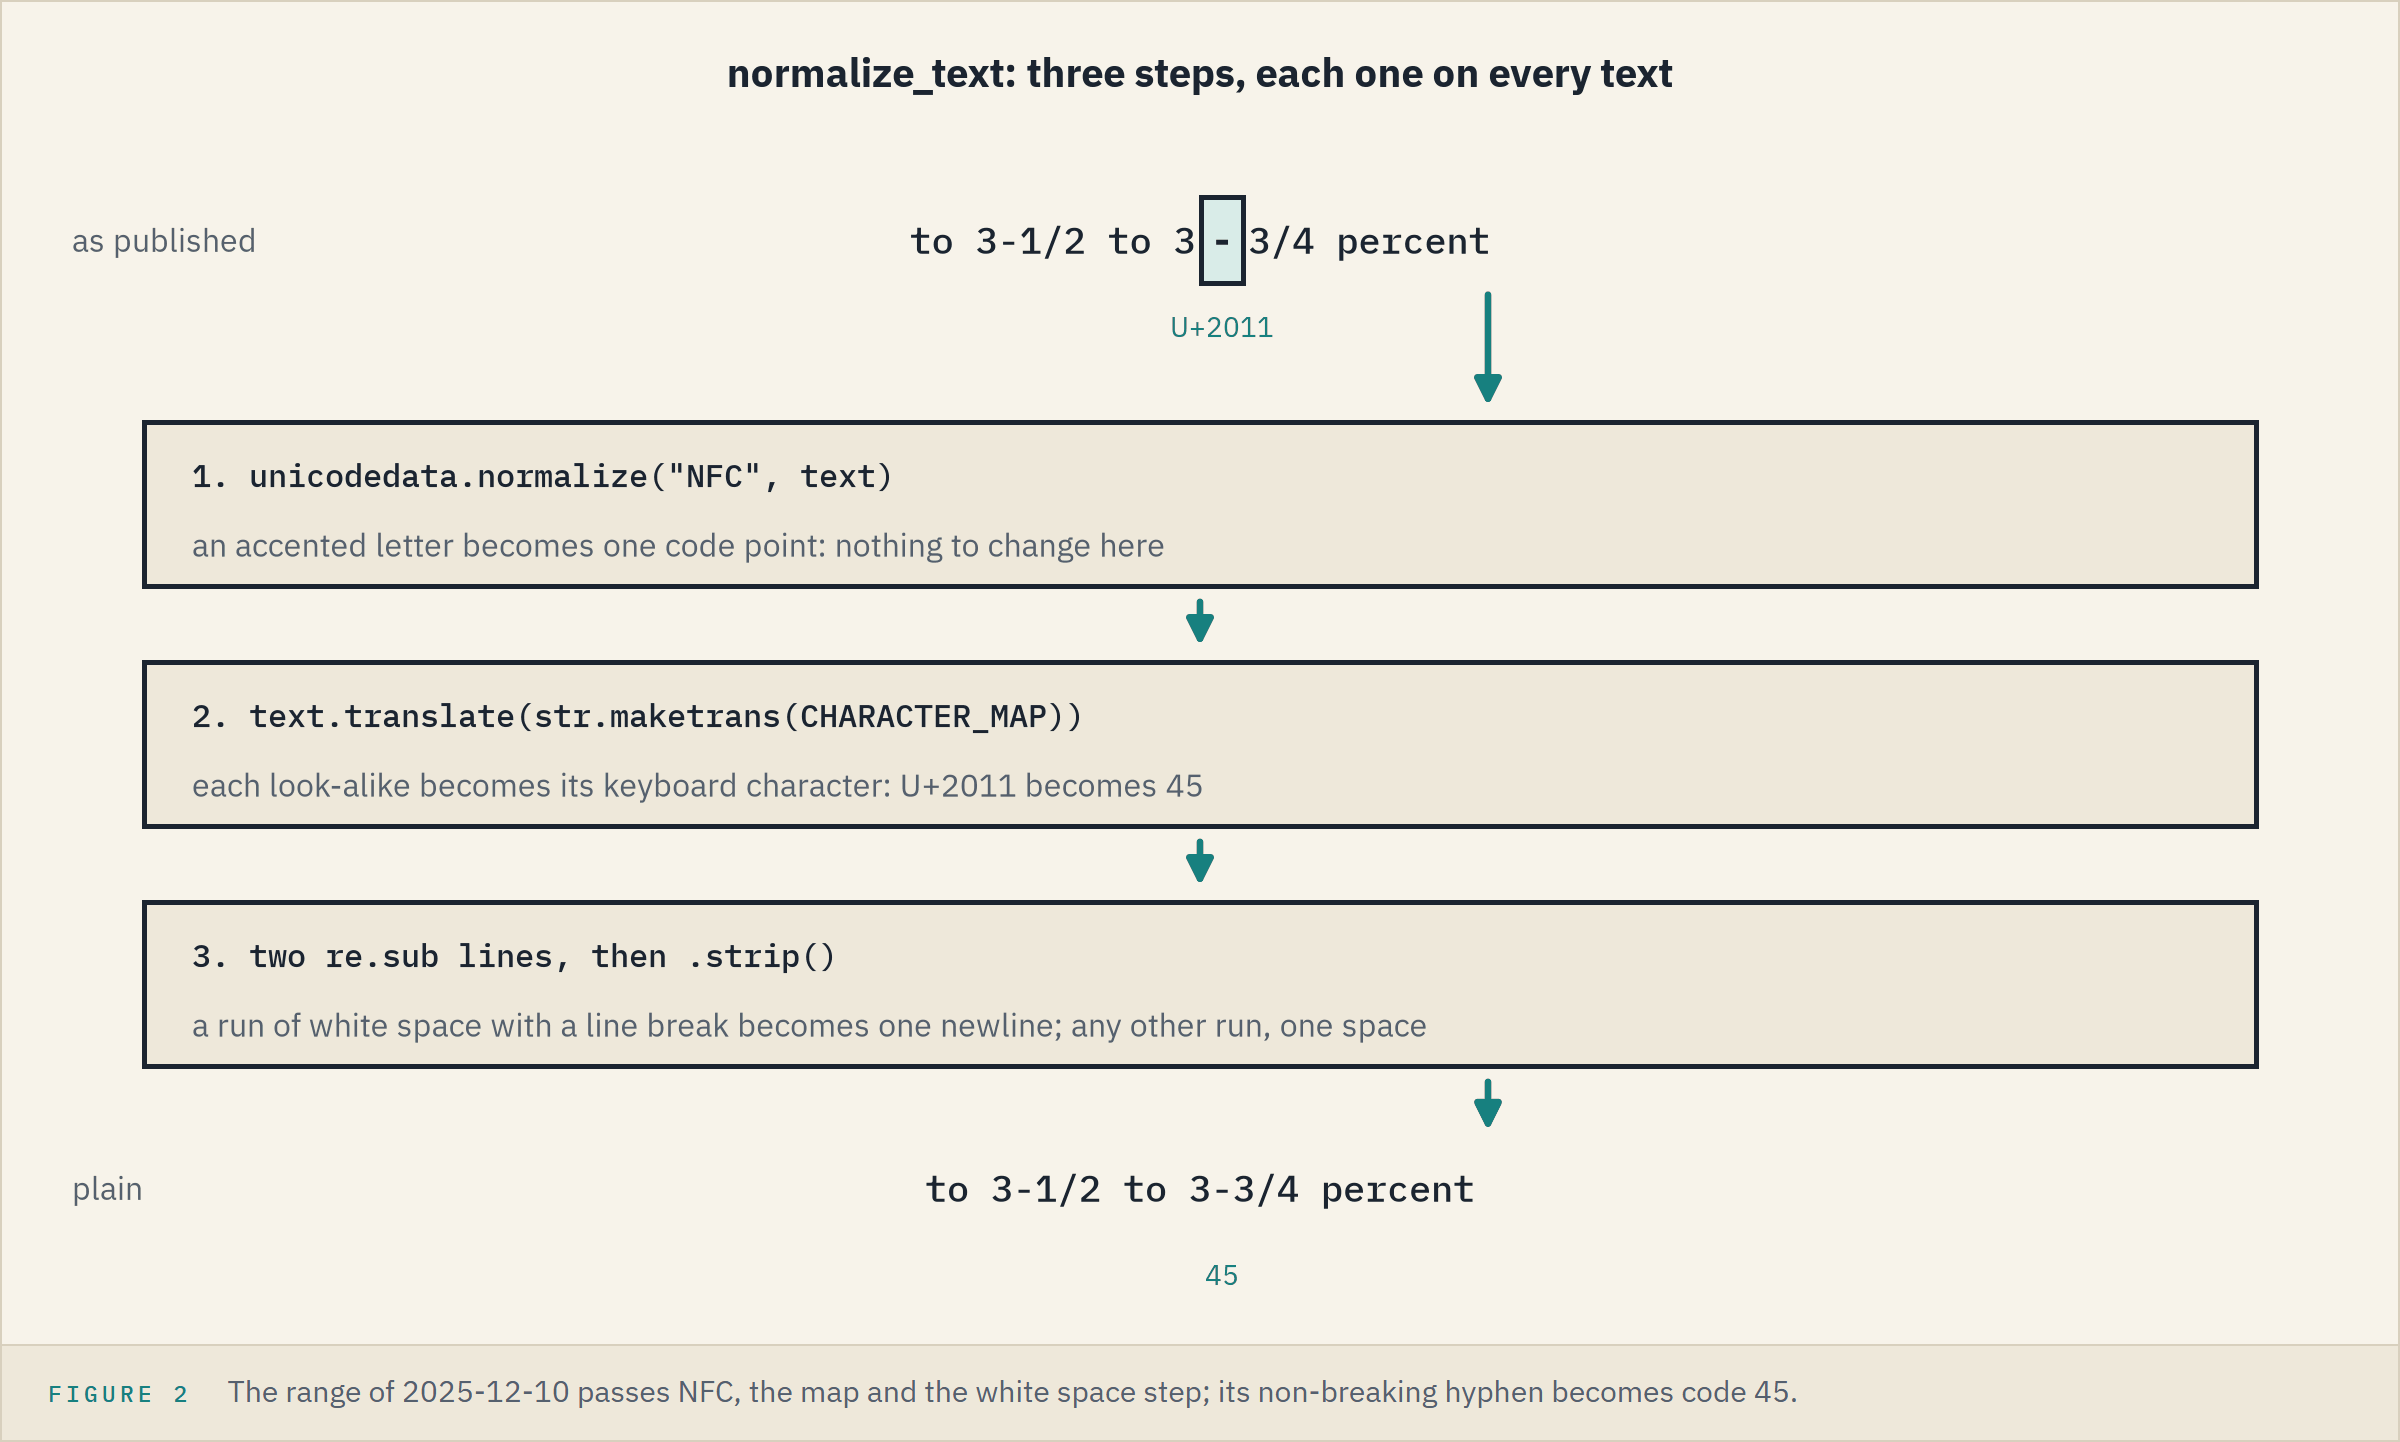

`[^\S\n]` is any white space but a newline (`\S` is any character that is not white space).

In [14]:
# NFC, then the map, then white space: a run holding a line break becomes one newline, any other run one space
def normalize_text(text):
    """Text with look-alike characters made plain and white space tidied."""
    text = unicodedata.normalize("NFC", text).translate(str.maketrans(CHARACTER_MAP))
    text = re.sub(r"[^\S\n]*\n\s*", "\n", text)
    text = re.sub(r"[^\S\n]+", " ", text)
    return text.strip()


# the white space step on a typed string: two spaces, then a blank line between two paragraphs
print(repr(normalize_text("Senior  Notes \n\n  due 2031")))

'Senior Notes\ndue 2031'


In [15]:
# every statement through normalize_text: what changed, what is left outside ASCII, and a second run
statements["clean"] = statements["text"].map(normalize_text)
print("statements changed:", (statements["clean"] != statements["text"]).sum())
print("characters above 127 left:", sum(ord(ch) > 127 for text in statements["clean"] for ch in text))
print("a second run changes", (statements["clean"].map(normalize_text) != statements["clean"]).sum(), "statements")
print('"longer-term" in', statements["clean"].str.contains("longer-term").sum(), "statements")

statements changed: 56
characters above 127 left: 0
a second run changes 0 statements
"longer-term" in 109 statements


56 statements change and nothing outside ASCII is left.

A second run changes nothing: the function is **idempotent**, so running it twice is safe.

**Every pattern and count from here runs on the `clean` column; the `text` column keeps the Board's characters as published.**

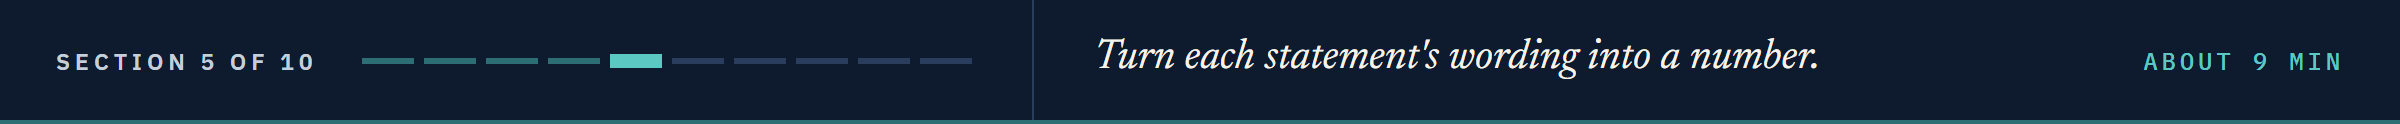

# Reading the Rate From Every Statement

## Course 1's Pattern on 226 Statements

In [16]:
# Course 1's range pattern on every cleaned statement: how many hold a match, and the first date with one
course1 = statements["clean"].str.contains(r"[\d/-]+ to [\d/-]+ percent")
print(course1.sum(), "statements | first:", statements["date"][course1].min())

146 statements | first: 2008-12-16


Nothing matches before 2008-12-16: earlier statements state one number, a target, which a range pattern cannot see.

## Three Wordings, One Number Piece

A statement writes its rate in one of a few **wordings**, each one a pattern.
An `rf"..."` string is raw and an f-string at once, so one `NUMBER` piece drops into each pattern as `{NUMBER}`.
`(?P<low>...)` is a **named group**: the match keeps what it holds under that name, read as `found["low"]`.

In [17]:
# a rate as written: a whole number with a fraction, a fraction alone, or a whole number
NUMBER = r"(?:\d+[- ]\d+/\d+|\d+/\d+|\d+)"
print(re.findall(NUMBER, "to 5-3/4 percent, 1 3/4 percent, by 1/4 percentage point, to 4 percent"))

# three wordings, tried in this order: a range, the current range, a single target
RANGE = (rf"target range for the federal funds rate(?: by {NUMBER} percentage point,?)?"
         rf" (?:at|to|of) (?P<low>{NUMBER}) to (?P<high>{NUMBER}) percent")
CURRENT = rf"(?P<low>{NUMBER}) to (?P<high>{NUMBER}) percent target range"
TARGET = rf"target for the federal funds rate[^.]*? (?:to|at) (?P<target>{NUMBER}) percent"
WORDINGS = {"range": RANGE, "current": CURRENT, "target": TARGET}

['5-3/4', '1 3/4', '1/4', '4']


`stated_rate(text)` returns the first wording that matches, with the rate's two ends as written (a target's two ends are the same number).

In [18]:
# the first wording that matches, with the low and high ends as written
def stated_rate(text):
    """The kind of rate a statement states, with its low and high ends as written."""
    for kind, pattern in WORDINGS.items():
        found = re.search(pattern, text)
        if found and kind == "target":
            return kind, found["target"], found["target"]
        if found:
            return kind, found["low"], found["high"]
    return "none", None, None


# every cleaned statement's rate, then a count of each kind
rates = pd.DataFrame(statements["clean"].map(stated_rate).tolist(), columns=["kind", "low", "high"])
print(rates["kind"].value_counts().to_dict())
print("last target:", statements["date"][rates["kind"] == "target"].max(),
      "| first range:", statements["date"][rates["kind"].isin(["range", "current"])].min())

{'range': 130, 'target': 76, 'current': 14, 'none': 6}
last target: 2008-10-29 | first range: 2008-12-16


## What the Pattern Matched

In [19]:
# RANGE on the latest statement: the words it matched, then its two groups
found = re.search(RANGE, statements["clean"].iloc[-1])
print(found.group(0))
print(found["low"], "|", found["high"])

target range for the federal funds rate by 1/4 percentage point to 3-3/4 to 4 percent
3-3/4 | 4


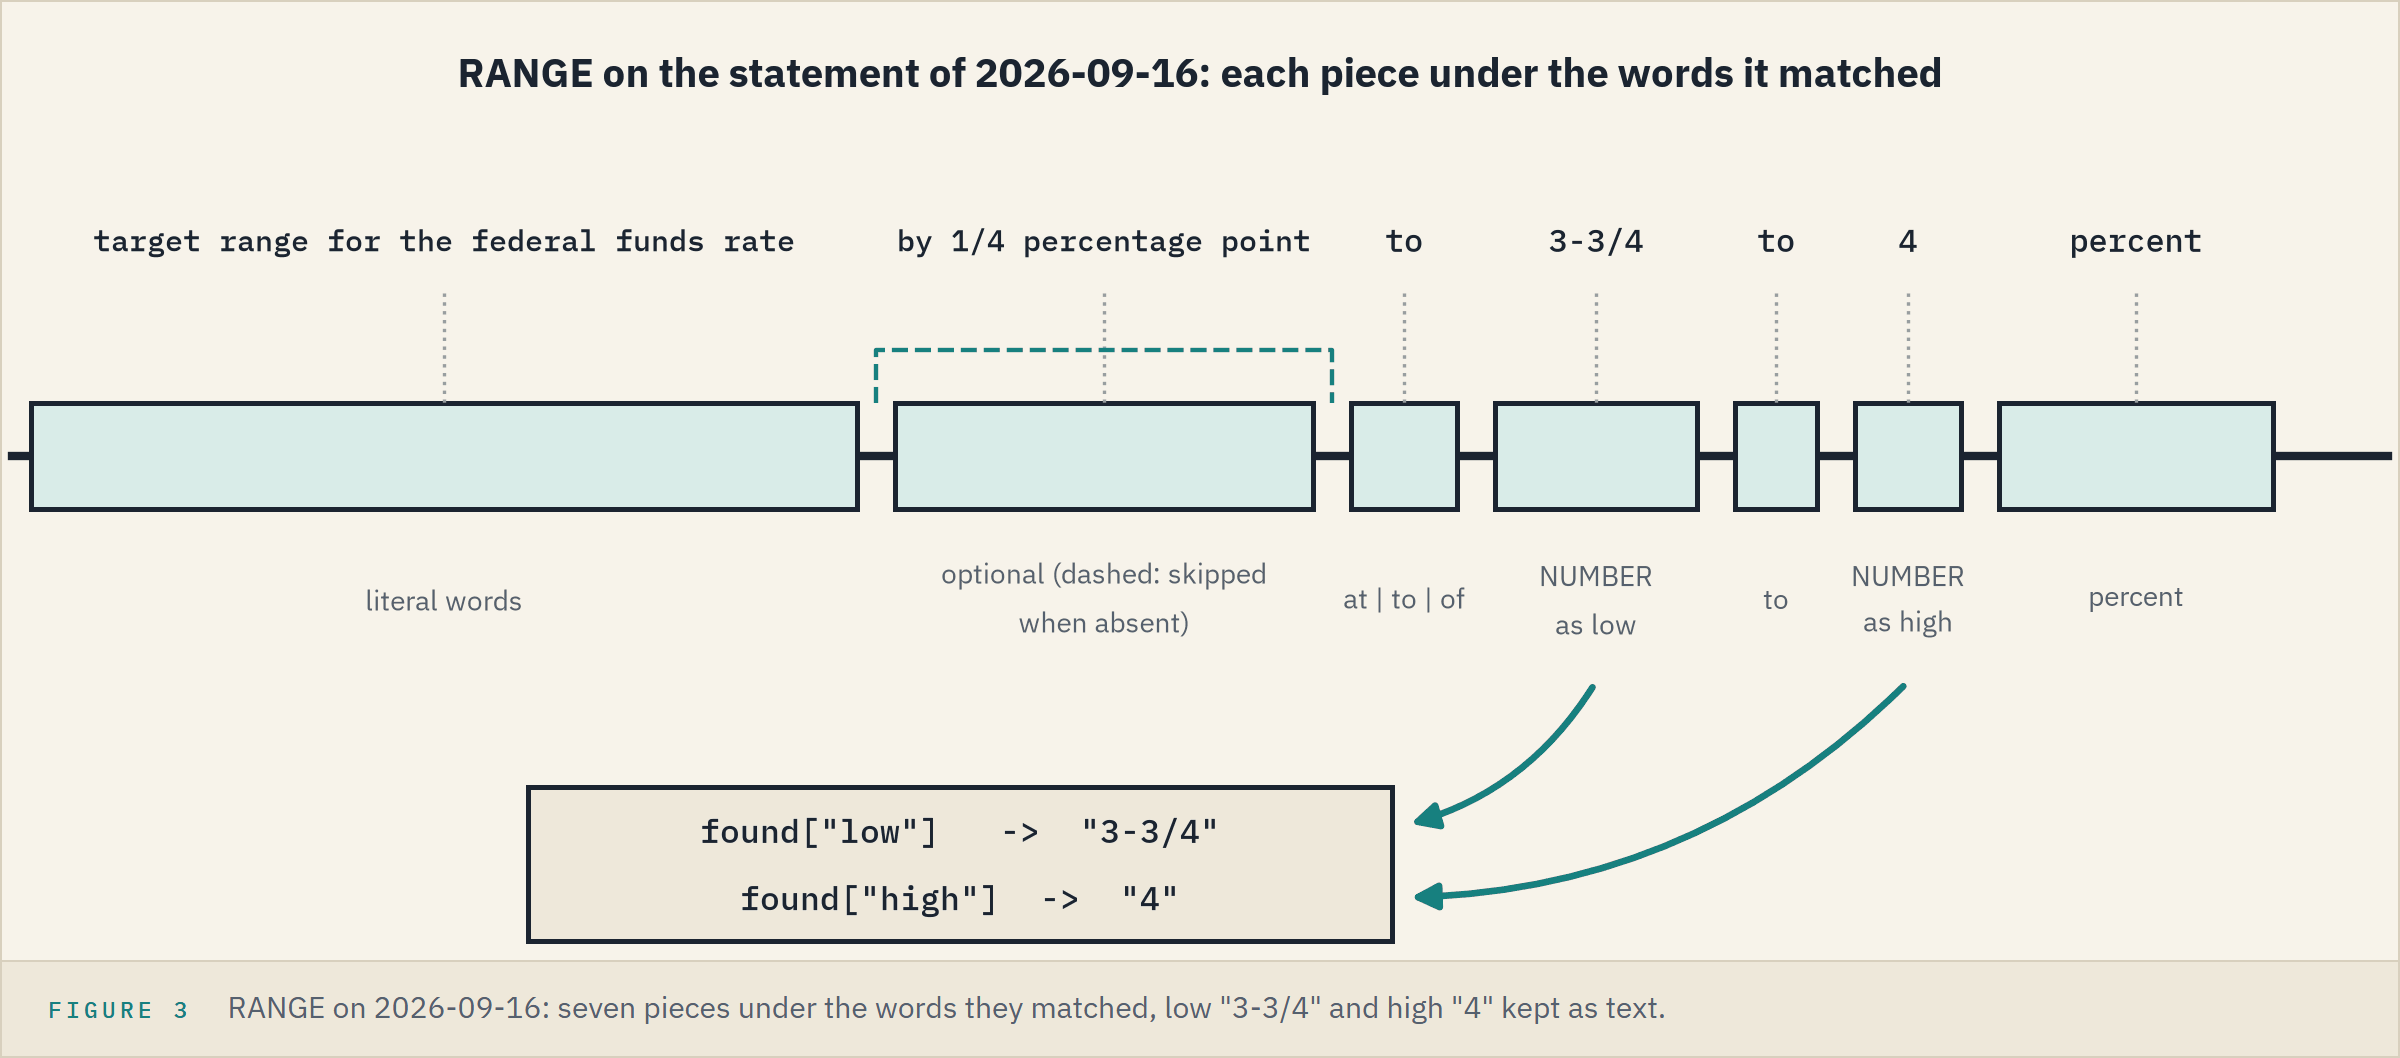

The optional piece is skipped where a statement gives no step, and the fork takes "at", "to" or "of".

The groups hold text: "3-3/4" is not yet a number.

## The Six With No Rate

In [20]:
# the statements no wording matched: scheduled or not, and what Course 1's pattern finds in each
empty = statements[rates["kind"] == "none"]
for date, scheduled, clean in zip(empty["date"], empty["scheduled"], empty["clean"]):
    print(date, scheduled, re.findall(r"[\d/-]+ to [\d/-]+ percent", clean))

2007-08-10 False []
2007-08-17 False []
2008-03-11 False []
2010-05-09 False []
2019-10-11 False ['1-3/4 to 2 percent']
2020-03-23 False ['0 to 1/4 percent']


In [21]:
# source text: quoted as published
# the Desk's directive in the two statements where Course 1's pattern finds a range
for date in ["2019-10-11", "2020-03-23"]:
    row = statements[statements["date"] == date].iloc[0]
    start = row["clean"].find("directs the Desk")
    print(row["clean"][start:row["clean"].find(" percent", start) + 8])
    statement_source(row)

directs the Desk to undertake open market operations as necessary to maintain the federal funds rate in a target range of 1-3/4 to 2 percent
Source: FOMC post-meeting statement of 2019-10-11, Board of Governors of the Federal Reserve System, https://www.federalreserve.gov/newsevents/pressreleases/monetary20191011a.htm
directs the Desk to undertake open market operations as necessary to maintain the federal funds rate in a target range of 0 to 1/4 percent
Source: FOMC post-meeting statement of 2020-03-23, Board of Governors of the Federal Reserve System, https://www.federalreserve.gov/newsevents/pressreleases/monetary20200323a.htm


All six follow unscheduled meetings, and two state a range in the Desk's own wording.

An earlier version of this course said the six name no target or range; two of them do.

In [22]:
# a fourth wording, the Desk's directive, then every statement again with all four
DIRECTIVE = rf"federal funds rate in a target range of (?P<low>{NUMBER}) to (?P<high>{NUMBER}) percent"
WORDINGS = {"range": RANGE, "current": CURRENT, "directive": DIRECTIVE, "target": TARGET}
rates = pd.DataFrame(statements["clean"].map(stated_rate).tolist(), columns=["kind", "low", "high"])
print(rates["kind"].value_counts().to_dict())
print("no rate:", statements["date"][rates["kind"] == "none"].tolist())

{'range': 130, 'target': 76, 'current': 14, 'none': 4, 'directive': 2}
no rate: ['2007-08-10', '2007-08-17', '2008-03-11', '2010-05-09']


Four statements state no rate as a number.

**Read the rows a pattern leaves empty before you trust its count.**

**Predict 2**

The four wordings find 146 ranges in the cleaned text.

Q. How many do they find in the text as published? Write down a number.

## The Same Patterns on the Raw Text

In [23]:
# the four wordings on the text as published, against the cleaned text
raw = pd.DataFrame(statements["text"].map(stated_rate).tolist(), columns=["kind", "low", "high"])
ranges = rates["kind"].isin(["range", "current", "directive"])
raw_ranges = raw["kind"].isin(["range", "current", "directive"])
print("ranges, cleaned:", ranges.sum(), "| as published:", raw_ranges.sum())

# the statements whose range is lost: their dates, whether they hold U+2011, and what the raw text gave instead
lost = statements[ranges & ~raw_ranges]
print(len(lost), "lost, from", lost["date"].min(), "to", lost["date"].max())
print("holding U+2011:", lost["text"].str.contains(chr(0x2011)).sum(), "| raw kind:", raw["kind"][lost.index].value_counts().to_dict())

ranges, cleaned: 146 | as published: 134
12 lost, from 2017-12-13 to 2026-04-29
holding U+2011: 12 | raw kind: {'none': 12}


12 ranges vanish, every one with a non-breaking hyphen inside a fraction.

Nothing fails: each row quietly becomes "none".

## From Text to Number

In [24]:
# "5-3/4" is 5 and 3/4: split at the hyphen, then add each part, a fraction as top over bottom
def written_to_number(written):
    """A rate as the statements write it ("5-3/4", "1 3/4", "1/4", "4") as a number of percent."""
    number = 0.0
    for part in written.replace(" ", "-").split("-"):
        if "/" in part:
            top, bottom = part.split("/")
            number += int(top) / int(bottom)
        else:
            number += int(part)
    return number


# one example of each way a rate is written, worked by hand, beside the function's number
hand = {"0": 0.0, "4": 4.0, "1/4": 0.25, "3/4": 0.75, "1 3/4": 1.75, "5-3/4": 5.75, "6-1/2": 6.5}
for written, by_hand in hand.items():
    print(repr(written), by_hand, written_to_number(written), by_hand == written_to_number(written))

'0' 0.0 0.0 True
'4' 4.0 4.0 True
'1/4' 0.25 0.25 True
'3/4' 0.75 0.75 True
'1 3/4' 1.75 1.75 True
'5-3/4' 5.75 5.75 True
'6-1/2' 6.5 6.5 True


`.map(function, na_action="ignore")` leaves an empty cell empty instead of passing it to the function.

In [25]:
# the rate's two ends in percent, added to the statements; then every written form, as a number
statements[["kind", "low", "high"]] = rates
statements["low_percent"] = statements["low"].map(written_to_number, na_action="ignore")
statements["high_percent"] = statements["high"].map(written_to_number, na_action="ignore")
forms = sorted(set(statements["low"].dropna()) | set(statements["high"].dropna()), key=written_to_number)
print(len(forms), "written forms:", [written_to_number(form) for form in forms])

# the highest stated rate, and the statements that state 0 to 1/4 percent
top = statements.loc[statements["high_percent"].idxmax()]
print("highest:", top["high_percent"], "percent on", top["date"])
print("0 to 1/4 percent:", ((statements["low_percent"] == 0) & (statements["high_percent"] == 0.25)).sum(), "statements")

28 written forms: [0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.25, 1.5, 1.75, 1.75, 2.0, 2.25, 2.5, 2.75, 3.0, 3.25, 3.5, 3.75, 4.0, 4.25, 4.5, 4.75, 5.0, 5.25, 5.5, 5.75, 6.0, 6.5]
highest: 6.5 percent on 2000-05-16
0 to 1/4 percent: 73 statements


Every form lands on a step of 0.25 percent; 1.25 and 1.75 appear twice because five 2002 statements write "1 1/4" or "1 3/4" with a space.

## The Rate Every Statement States

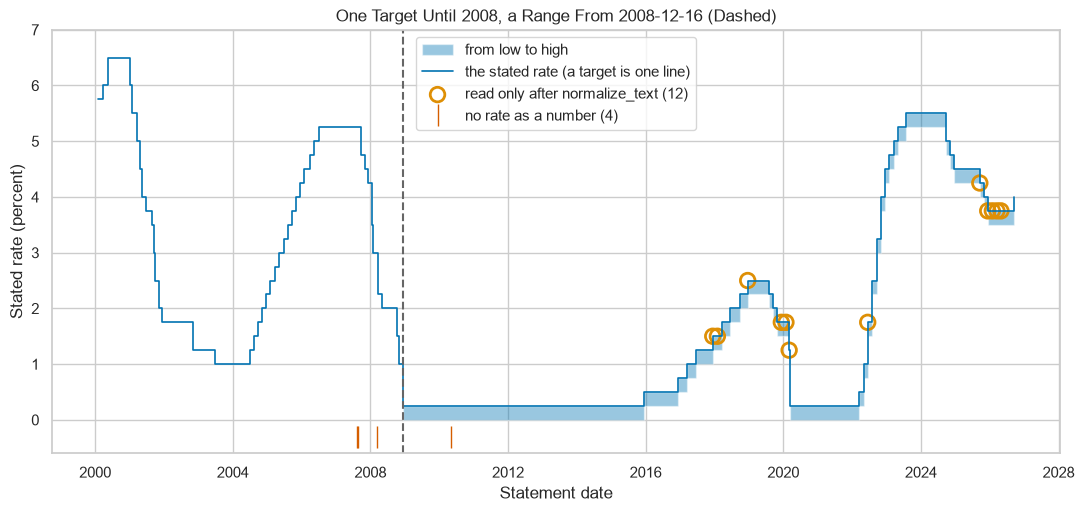

In [26]:
# the stated rate through time: a band from low to high, the 12 read only after cleaning ringed, the 4 with none ticked
stated = statements[statements["kind"] != "none"]
when = pd.to_datetime(stated["date"])
ringed = stated.index.isin(lost.index)
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.fill_between(when, stated["low_percent"], stated["high_percent"], step="post", alpha=0.4, label="from low to high")
ax.step(when, stated["high_percent"], where="post", color="C0", linewidth=1.2, label="the stated rate (a target is one line)")
ax.scatter(when[ringed], stated["high_percent"][ringed], s=110, facecolors="none", edgecolors="C1", linewidths=2, label="read only after normalize_text (12)")
ax.plot(pd.to_datetime(statements["date"][statements["kind"] == "none"]), [-0.3] * 4, "|", color="C3", markersize=16, label="no rate as a number (4)")
ax.axvline(pd.Timestamp("2008-12-16"), color="0.4", linestyle="--")
ax.set(xlabel="Statement date", ylabel="Stated rate (percent)", ylim=(-0.6, 7))
ax.legend(loc="upper center")
ax.set_title("One Target Until 2008, a Range From 2008-12-16 (Dashed)")
plt.show()

### Interpretation of the Chart

Before 2008-12-16 each statement states one target; after it, a range a quarter point wide, shaded between its two ends.

The 12 ringed statements sit from 2017 on, where the non-breaking hyphen does.

A misread fraction would show as a jump its neighbours do not share, and none does.

**226 statements became a column of numbers, and 12 of them depend on `normalize_text`.**

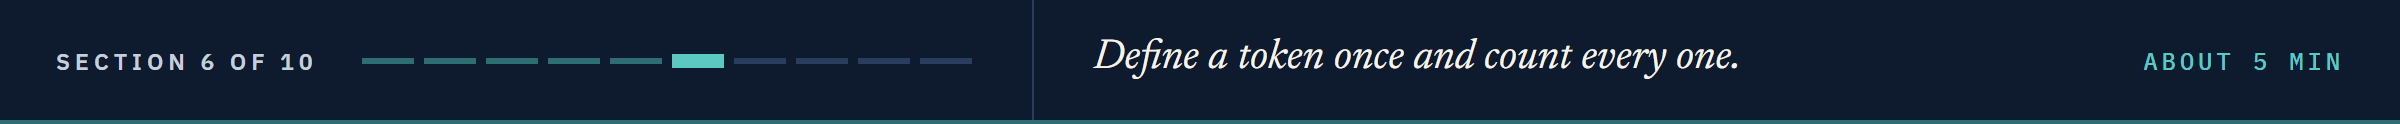

# Tokens

## A Token Pattern

A **token** is the unit a count is made of.
The course's token is a run of lower-case letters and digits, joined by single hyphens, apostrophes or full stops.

In [27]:
# the course's token: letters and digits, joined by one hyphen, apostrophe or full stop
TOKEN_PATTERN = r"[a-z0-9]+(?:[-'.][a-z0-9]+)*"


def tokenize(text):
    """The course's tokens of a text, in lower case, after normalize_text."""
    return re.findall(TOKEN_PATTERN, normalize_text(text).lower())


# Course 1's clean(), as its Text Analysis notebook wrote it, against tokenize on one phrase
def clean(text):
    text = re.sub(r"[^a-z\s]", " ", text.lower())
    text = re.sub(r"\s+", " ", text).strip()
    return text.split(" ")


phrase = "The Committee's mortgage-backed securities; the 4.750% notes; by 1/4 percentage point"
print(clean(phrase))
print(tokenize(phrase))

['the', 'committee', 's', 'mortgage', 'backed', 'securities', 'the', 'notes', 'by', 'percentage', 'point']
['the', "committee's", 'mortgage-backed', 'securities', 'the', '4.750', 'notes', 'by', '1', '4', 'percentage', 'point']


`clean()` splits "mortgage-backed" and "Committee's" in two and drops "4.750"; `tokenize` keeps each whole.

"1/4" still gives "1" and "4": tokens count words, and the rate patterns read numbers.

## Every Token in the File

In [28]:
# every statement's tokens, then one count of each distinct token
statements["token_list"] = statements["text"].map(tokenize)
counts = Counter(token for tokens in statements["token_list"] for token in tokens)
print(sum(counts.values()), "tokens |", len(counts), "distinct")
print("the first statement:", len(statements["text"][0].split()), "pieces at white space,", len(statements["token_list"][0]), "tokens")

# the hyphenated tokens, and the statements that hold two of them
hyphenated = Counter({token: n for token, n in counts.items() if "-" in token})
print(len(hyphenated), "distinct hyphenated |", hyphenated.most_common(2))
for word in ["mortgage-backed", "longer-term"]:
    holds = [word in tokens for tokens in statements["token_list"]]
    print(word, "in", sum(holds), "statements, from", year[holds].min(), "to", year[holds].max())

86576 tokens | 1910 distinct
the first statement: 188 pieces at white space, 190 tokens
62 distinct hyphenated | [('mortgage-backed', 215), ('longer-term', 204)]
mortgage-backed in 108 statements, from 2008 to 2025
longer-term in 113 statements, from 2000 to 2021


"longer-term" counts in 113 statements, 4 more than the cleaned text matched: tokens are lower case, and those 4 write "Longer-term".

## Stop Words

**Stop words** are common words a count often drops.
scikit-learn's `ENGLISH_STOP_WORDS` is one fixed set of them (Course 1 used nltk's list).

In [29]:
# the size of the list, and the share of all tokens it would drop
all_tokens = sum(counts.values())
stop_tokens = sum(n for token, n in counts.items() if token in ENGLISH_STOP_WORDS)
print(len(ENGLISH_STOP_WORDS), "stop words |", stop_tokens, "tokens,", round(100 * stop_tokens / all_tokens, 1), "percent")

# four words a credit reader keeps, tested one at a time, and how often the indenture uses each
boyd_counts = Counter(tokenize(boyd_raw))
for word in ["interest", "amount", "not", "below"]:
    print(word, word in ENGLISH_STOP_WORDS, "| in the indenture:", boyd_counts[word])

318 stop words | 32693 tokens, 37.8 percent
interest True | in the indenture: 367
amount True | in the indenture: 216
not True | in the indenture: 417
below True | in the indenture: 21


The list is general English: it holds "interest", "amount", "not" and "below", words a bond reader cannot drop.

So the course drops stop words only where a day says so.

## Rank and Frequency

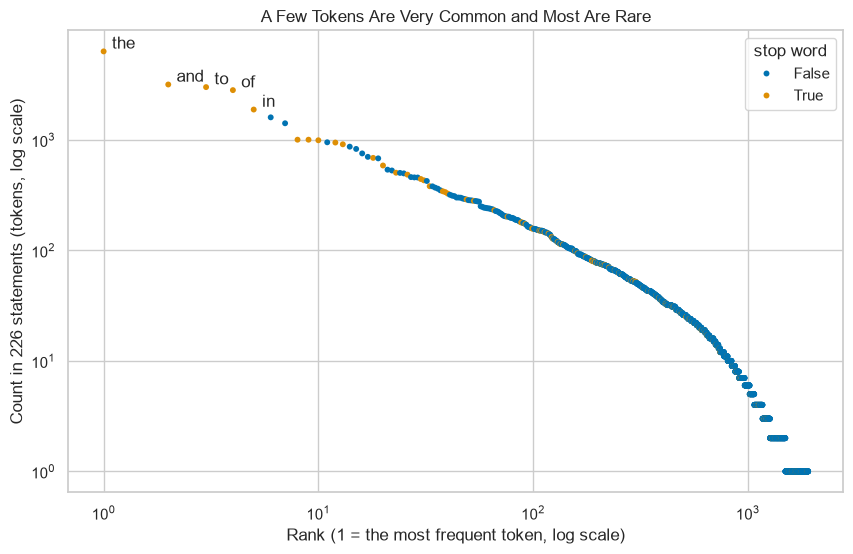

stop words in the top 10: 8
tokens that make half of all tokens: 52
tokens seen once: 415
[['committee', 1601], ['inflation', 1415], ['economic', 952], ['federal', 869], ['rate', 829], ['policy', 755], ['percent', 703], ['market', 681], ['conditions', 538], ['2', 529], ['funds', 503], ['monetary', 498], ['securities', 461], ['labor', 458], ['range', 457]]


In [30]:
# every distinct token by rank and count, stop words in orange, on log-log axes, the top five named
ranked = pd.DataFrame(counts.most_common(), columns=["token", "count"])
ranked["rank"] = np.arange(1, len(ranked) + 1)
ranked["stop word"] = ranked["token"].isin(list(ENGLISH_STOP_WORDS))
plt.figure(figsize=(10, 6))
sns.scatterplot(data=ranked, x="rank", y="count", hue="stop word", s=18, linewidth=0)
for token, count, rank in ranked[["token", "count", "rank"]].head(5).itertuples(index=False):
    plt.annotate(token, (rank, count), xytext=(6, 2), textcoords="offset points")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Rank (1 = the most frequent token, log scale)")
plt.ylabel("Count in 226 statements (tokens, log scale)")
plt.title("A Few Tokens Are Very Common and Most Are Rare")
plt.show()

# stop words in the top 10, the tokens that make half of all tokens, the tokens seen once, the top 15 without stop words
print("stop words in the top 10:", ranked["stop word"].head(10).sum())
print("tokens that make half of all tokens:", (ranked["count"].cumsum() < all_tokens / 2).sum() + 1)
print("tokens seen once:", (ranked["count"] == 1).sum())
print(ranked.loc[~ranked["stop word"], ["token", "count"]].head(15).values.tolist())

The points fall close to a straight line on these axes, the pattern named **Zipf's law**.

8 of the 10 most frequent tokens are stop words, and 52 tokens make half of the file.

## Your Turn: One Word, Year by Year

Pick a token and watch the share of each year's statements that hold it.

In [31]:
# the share of each year's statements holding a token, for the token you pick
def word_share(word):
    holds = pd.Series([word in tokens for tokens in statements["token_list"]])
    share = holds.groupby(year).mean()
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.bar(share.index, share, color="C0")
    ax.set(xlabel="Year", ylabel="Share of statements", ylim=(0, 1.05), title=f'Share of Statements Holding "{word}", by Year')
    ax.tick_params(axis="x", rotation=90)
    plt.show()


interact(word_share, word=["mortgage-backed", "longer-term", "unemployment", "pandemic", "energy", "housing"]);

interactive(children=(Dropdown(description='word', options=('mortgage-backed', 'longer-term', 'unemployment', …

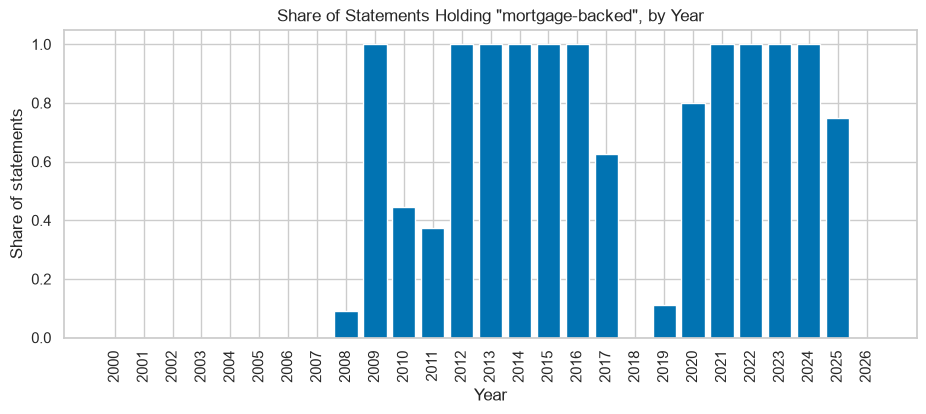

In [32]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
word_share("mortgage-backed")

"mortgage-backed" appears from 2008 to 2025, and in every statement of 2009, of 2012 to 2016 and of 2021 to 2024.

## The Cleaning Ladder in One Table

In [33]:
# six rungs, from pieces at white space to tokens with a letter: the pieces and distinct pieces of each
texts = statements["text"]
rungs = {"split at white space": [piece for text in texts for piece in text.split()],
         "lower case": [piece for text in texts for piece in text.lower().split()],
         "normalize_text, lower case": [piece for text in texts for piece in normalize_text(text).lower().split()],
         "tokens": [token for tokens in statements["token_list"] for token in tokens]}
rungs["stop words dropped"] = [token for token in rungs["tokens"] if token not in ENGLISH_STOP_WORDS]
rungs["tokens with no letter dropped"] = [token for token in rungs["stop words dropped"] if re.search("[a-z]", token)]
pd.DataFrame({"pieces": [len(v) for v in rungs.values()], "distinct": [len(set(v)) for v in rungs.values()]}, index=rungs.keys())

,pieces,distinct
split at white space,86191,2741
lower case,86191,2586
"normalize_text, lower case",86191,2573
tokens,86576,1910
stop words dropped,53883,1746
tokens with no letter dropped,52383,1682


Lower case folds 155 distinct pieces together; the token pattern folds 663 more by taking punctuation off words.

**A token is defined once, and every count in this course uses it.**

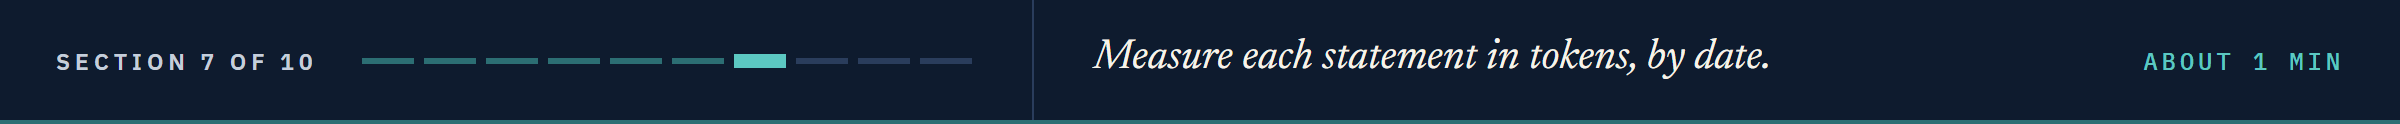

# How Long the Statements Are

**Predict 3**

Q. Sketch the median number of tokens per statement, year by year, from 2000 to 2026: where does it start, where does it peak, and where does it end?

## Tokens per Statement

{'2000': 178.0, '2007': 175.0, '2014': 822.5, '2026': 232.0}
2014-09-17 896 tokens
2007-08-10 79 tokens
median, scheduled: 352.0 | unscheduled: 253.0


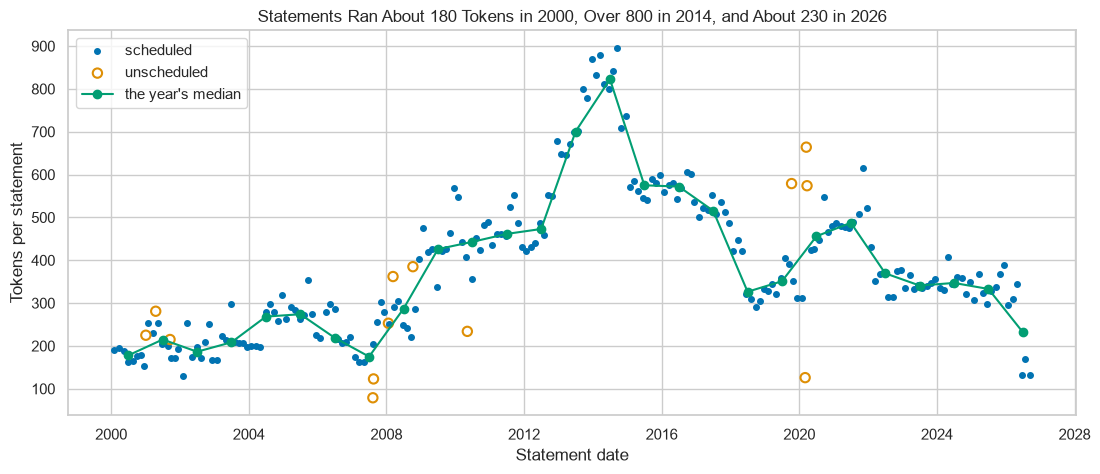

In [34]:
# tokens in each statement, the median of four years, the longest and shortest, and the median after each kind of meeting
statements["tokens"] = statements["token_list"].map(len)
median = statements.groupby(year)["tokens"].median()
print(median.loc[["2000", "2007", "2014", "2026"]].to_dict())
for row_number in [statements["tokens"].idxmax(), statements["tokens"].idxmin()]:
    print(statements.loc[row_number, "date"], statements.loc[row_number, "tokens"], "tokens")
print("median, scheduled:", statements.loc[statements["scheduled"], "tokens"].median(),
      "| unscheduled:", statements.loc[~statements["scheduled"], "tokens"].median())

# each statement's tokens by date, unscheduled ones hollow, each year's median as a line
when = pd.to_datetime(statements["date"])
plt.figure(figsize=(13, 5))
plt.scatter(when[statements["scheduled"]], statements["tokens"][statements["scheduled"]], s=16, label="scheduled")
plt.scatter(when[~statements["scheduled"]], statements["tokens"][~statements["scheduled"]], s=45, facecolors="none",
            edgecolors="C1", linewidths=1.5, label="unscheduled")
plt.plot(pd.to_datetime(median.index + "-07-01"), median, color="C2", marker="o", label="the year's median")
plt.xlabel("Statement date")
plt.ylabel("Tokens per statement")
plt.legend(loc="upper left")
plt.title("Statements Ran About 180 Tokens in 2000, Over 800 in 2014, and About 230 in 2026")
plt.show()

### Interpretation of the Chart

The yearly median runs 178 tokens in 2000 and 175 in 2007, peaks at 822.5 in 2014, and is 232 in 2026's six statements.

The longest statement is 2014-09-17's, 896 tokens; the shortest, 2007-08-10's, 79, follows an unscheduled meeting.

Unscheduled statements are shorter at the median, 253 tokens against 352.

**Counts describe the documents by date; why their length moved is not in them.**

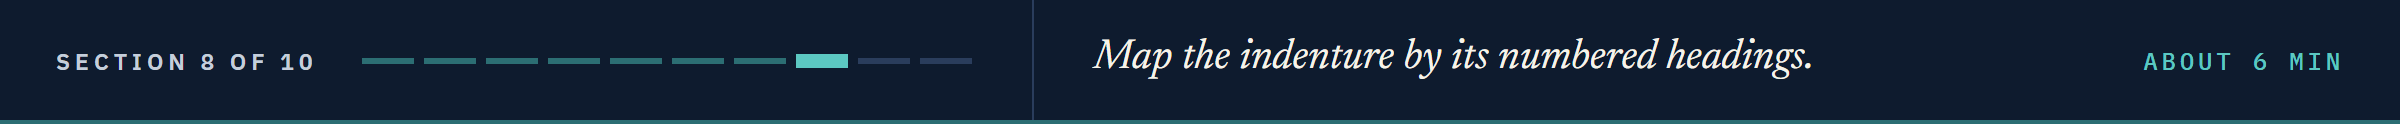

# The Indenture's Sections

## A First Look

An **indenture** is the contract between an issuer and a **trustee**, who acts for the noteholders.
It is split into **articles**, each article into numbered **sections**, and the issuer's promises about what it may and may not do are its **covenants**.

In [35]:
# the line that names the indenture under every excerpt, with a section number when there is one
def boyd_source(section=None):
    """Print the source line of the Boyd indenture, or of one of its sections."""
    where = f", Section {section}" if section else ""
    print("Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed "
          f"2021-06-08, accession 0001193125-21-185495{where}.")


# the indenture's size in words, tokens and lines
print(len(boyd_raw.split()), "words |", sum(boyd_counts.values()), "tokens |", len(boyd_raw.split("\n")), "lines")

63595 words | 63810 tokens | 1714 lines


In [36]:
# source text: quoted as published
# the start of the indenture, through normalize_text: the cover, then the table of contents
boyd = normalize_text(boyd_raw)
print(boyd[:640])
boyd_source()

# the indenture's own characters above 127, by code point and name
for ch, times in Counter(ch for ch in boyd_raw if ord(ch) > 127).most_common():
    print(f"U+{ord(ch):04X}", unicodedata.name(ch), times)

EX-4.1 2 d185267dex41.htm EX-4.1
EX-4.1
Exhibit 4.1
Execution Version
BOYD GAMING CORPORATION
AND
THE GUARANTORS NAMED HEREIN
4.750% SENIOR NOTES DUE 2031
INDENTURE
Dated as of June 8, 2021
WILMINGTON TRUST, NATIONAL ASSOCIATION,
as Trustee
TABLE OF CONTENTS
Page
ARTICLE 1. DEFINITIONS AND INCORPORATION BY REFERENCE 1
Section 1.01. Definitions 1
Section 1.02. Other Definitions 31
Section 1.03. [Reserved] 32
Section 1.04. Rules of Construction 32
Section 1.05. Limited Condition Transactions 32
Section 1.06. Master Leases and Additional Leases 33
ARTICLE 2. THE NOTES 33
Section 2.01. Form; Dating; Execution and Authentication 33
Secti
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495.
U+2610 BALLOT BOX 36
U+00A7 SECTION SIGN 10
U+2044 FRACTION SLASH 1


The indenture brings three characters the statements never held: a ballot box for a form's tick boxes, the section sign, and one fraction slash, in "66 2/3%".

None is in the map; check each new document's characters before trusting it.

**Predict 4**

Q. How many lines of the indenture look like a section heading, such as "Section 4.12. Limitation on Indebtedness"? Write down a number.

## Lines That Look Like a Heading

`SECTION_PATTERN` reads a line that starts "Section" or "SECTION", a number such as 4.12, and a title that starts with a capital letter or "[", to the end of the line.
`re.finditer` returns every match in turn, each with its `.start()`.

In [37]:
# a heading line: Section or SECTION, a number with a full stop inside it, then a title to the end of the line
SECTION_PATTERN = r"^(?:Section|SECTION) (?P<number>\d+\.\d+)\.? (?P<title>[A-Z\[][^\n]*?)\.?$"
headings = list(re.finditer(SECTION_PATTERN, boyd, flags=re.MULTILINE))
print(len(headings), "heading lines |", len({heading["number"] for heading in headings}), "numbers")
print("4.12 starts at", [heading.start() for heading in headings if heading["number"] == "4.12"])

214 heading lines | 107 numbers
4.12 starts at [1996, 198454]


Every number has two heading lines: one in the table of contents, one in the body.

## `find_sections`

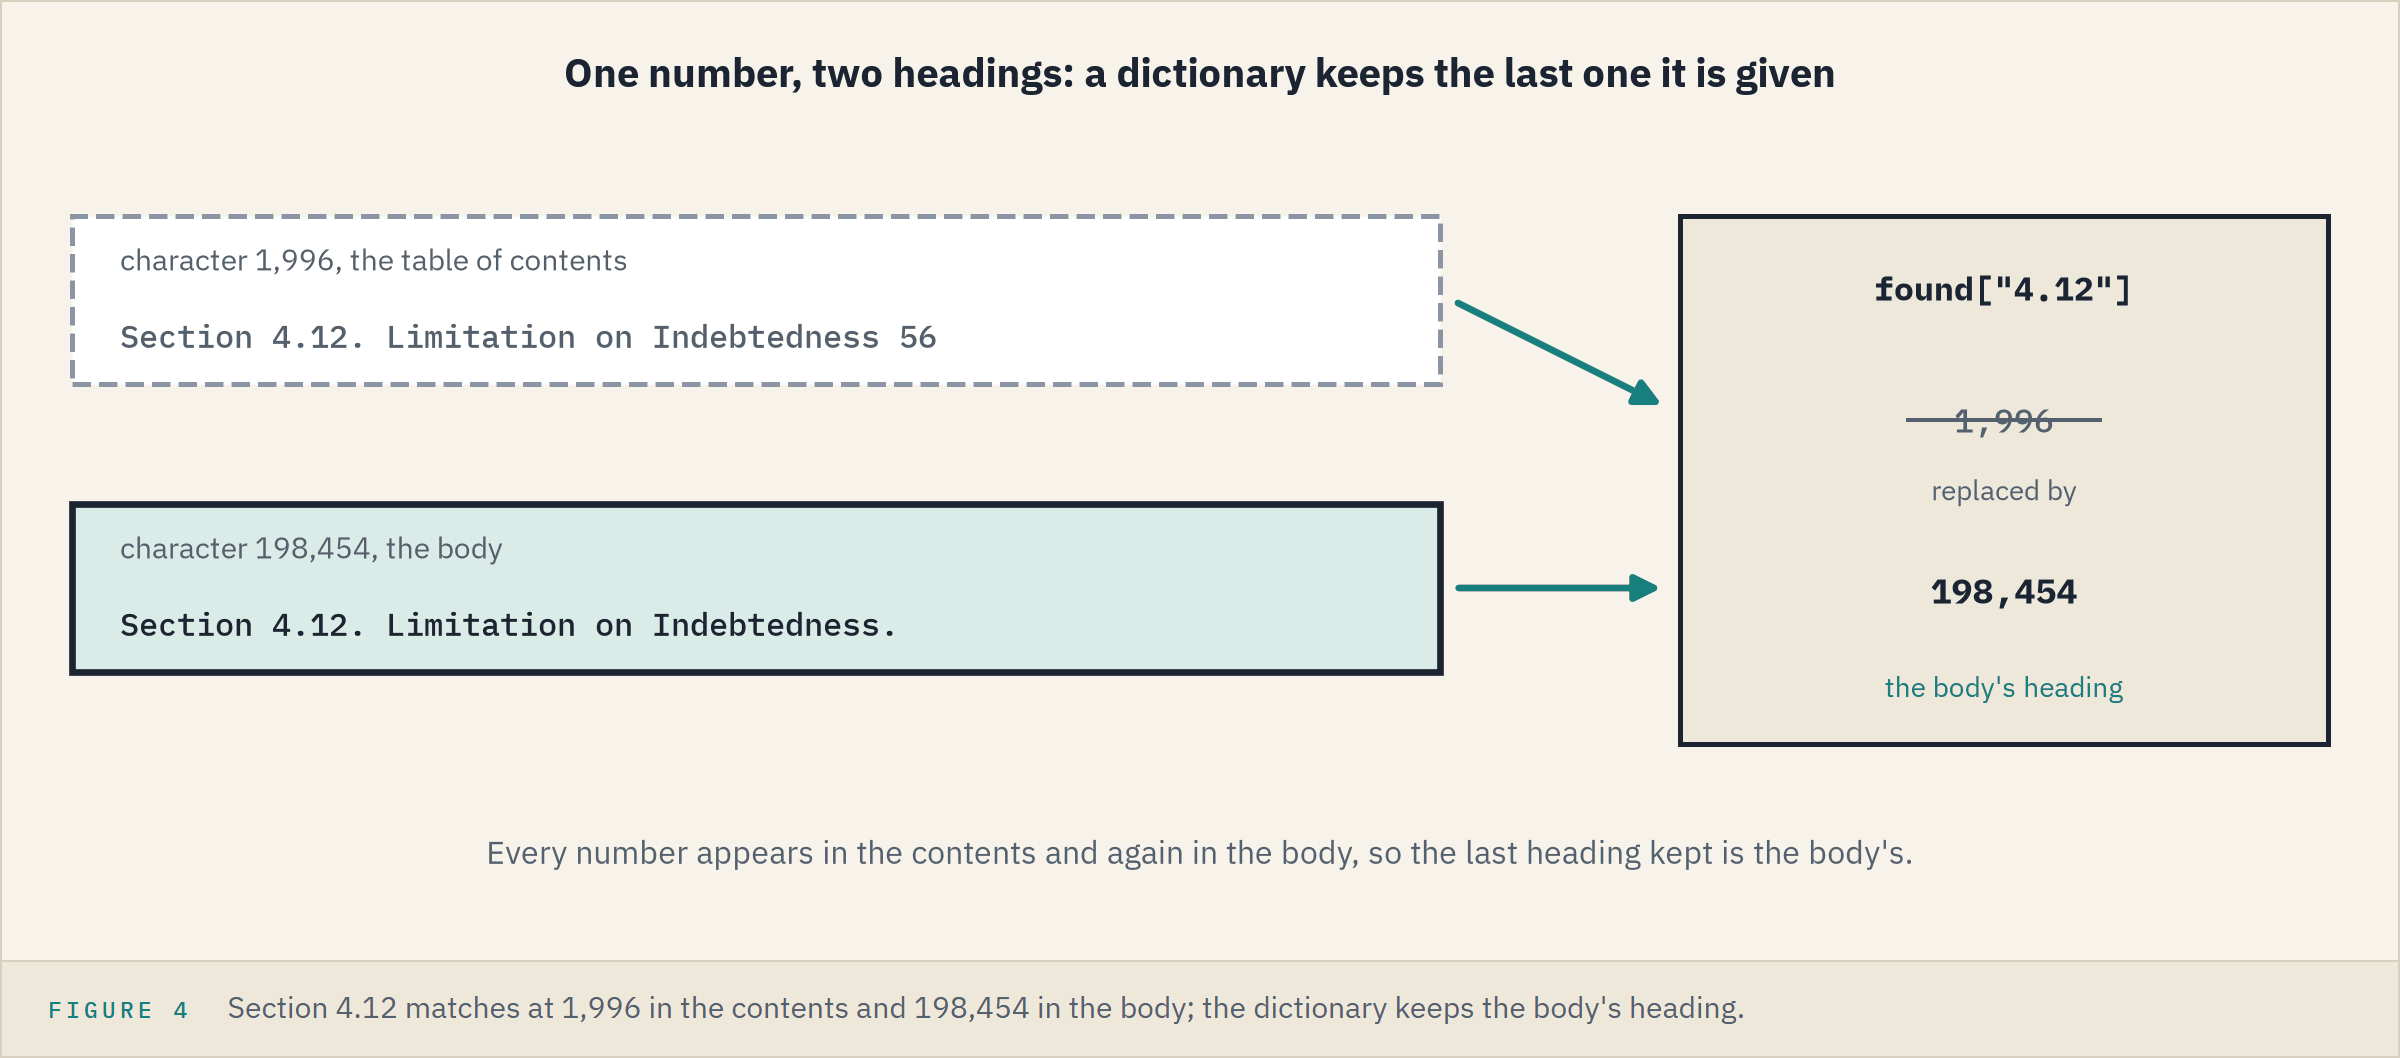

`find_sections` keeps each number's last heading in a dictionary, so the body's replaces the contents' line.
Each section then runs to the next one's start, which `.shift(-1)` reads from the row below.

In [38]:
# each number's last heading wins, then each section runs to the start of the next
def find_sections(text):
    """The sections of an indenture, in the order of the text: number as text, title, start and end."""
    found = {}
    for heading in re.finditer(SECTION_PATTERN, text, flags=re.MULTILINE):
        found[heading["number"]] = {"number": heading["number"], "title": heading["title"], "start": heading.start()}
    sections = pd.DataFrame(found.values()).sort_values("start", ignore_index=True)
    sections["end"] = sections["start"].shift(-1, fill_value=len(text))
    return sections


# the Boyd indenture's sections, with the words in each, and why a section number stays text
sections = find_sections(boyd)
sections["words"] = [len(boyd[start:end].split()) for start, end in zip(sections["start"], sections["end"])]
body = sections["start"].iloc[0]
print(len(sections), "sections, from", sections["number"].iloc[0], "to", sections["number"].iloc[-1])
print("the body starts at character", body, "after", len(boyd[:body].split()), "words of cover and contents")
print(float("4.10"), "|", "4.10", "|", sections["number"].dtype)

107 sections, from 1.01 to 12.14
the body starts at character 6551 after 997 words of cover and contents
4.1 | 4.10 | str


As a number, Section 4.10 would be 4.1, so every section number stays text.

## The Indenture by Article

{'1': 17697, '12': 12300} | Section 12.14: 10795 words


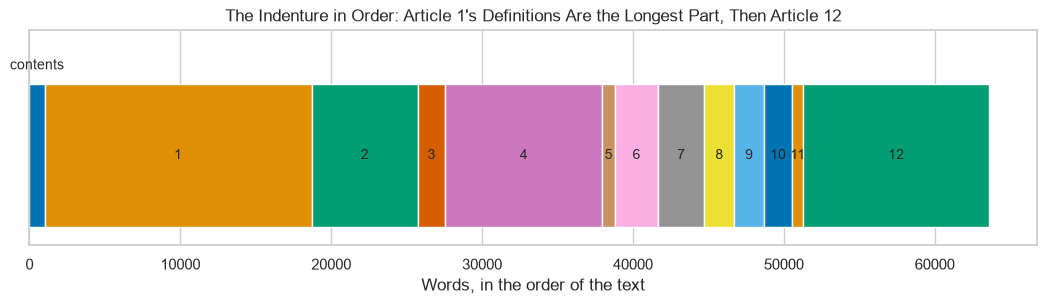

In [39]:
# the words in each article, after the cover and contents (labelled above the bar)
sections["article"] = sections["number"].str.split(".").str[0]
articles = sections.groupby("article", sort=False)["words"].sum()
parts = pd.concat([pd.Series({"contents": len(boyd[:body].split())}), articles])
print(articles.nlargest(2).to_dict(), "| Section 12.14:", sections.set_index("number").loc["12.14", "words"], "words")
fig, ax = plt.subplots(figsize=(13, 2.8))
ax.barh(0, parts, left=parts.cumsum() - parts, color=[f"C{i % 10}" for i in range(len(parts))], edgecolor="white")
for name, words, left in zip(parts.index, parts, parts.cumsum() - parts):
    ax.text(left + words / 2, 0.5 if name == "contents" else 0, name, ha="center", va="center", fontsize=10)
ax.set(yticks=[], ylim=(-0.5, 0.7), xlabel="Words, in the order of the text")
ax.set_title("The Indenture in Order: Article 1's Definitions Are the Longest Part, Then Article 12")
plt.show()

Article 1, the definitions, holds 17,697 words, and Article 12 holds 12,300.

Section 12.14 alone is 10,795 words: the signature pages, then Exhibits A to F.

## Article 4, the Covenants

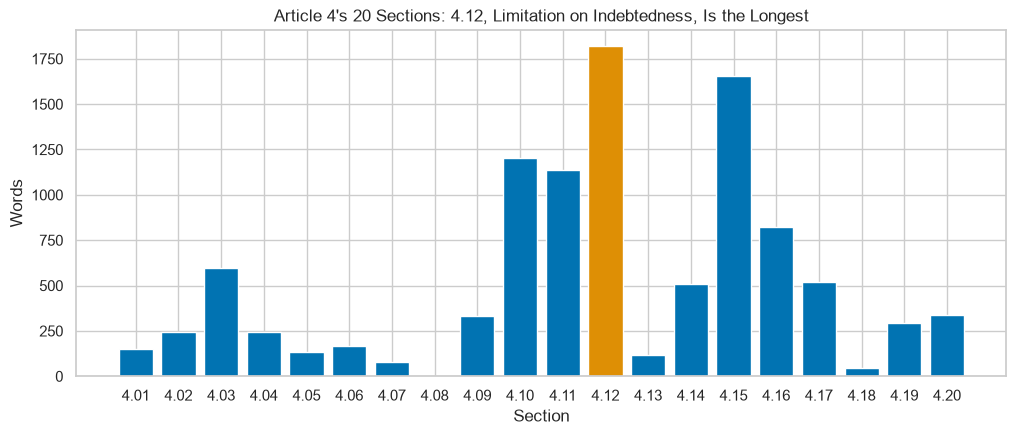

number                             title  words
  4.12        Limitation on Indebtedness   1819
  4.15 Limitation on Restricted Payments   1653
  4.10                 Change of Control   1204
  4.11                       Asset Sales   1138
Article 4: 10410 words | 4.12: 17.5 percent
4.08 [Reserved] 3


In [40]:
# the twenty sections of Article 4 by words, 4.12 in orange
article4 = sections[sections["article"] == "4"]
plt.figure(figsize=(12, 4.5))
plt.bar(article4["number"], article4["words"], color=["C1" if number == "4.12" else "C0" for number in article4["number"]])
plt.xlabel("Section")
plt.ylabel("Words")
plt.title("Article 4's 20 Sections: 4.12, Limitation on Indebtedness, Is the Longest")
plt.show()

# the four longest covenants with their titles, 4.12's share of the article, and the shortest section
print(article4.nlargest(4, "words")[["number", "title", "words"]].to_string(index=False))
share = 100 * article4.set_index("number").loc["4.12", "words"] / article4["words"].sum()
print("Article 4:", article4["words"].sum(), "words | 4.12:", round(share, 1), "percent")
print(article4.nsmallest(1, "words")[["number", "title", "words"]].to_string(index=False, header=False))

Article 4 runs from 4.01 to 4.20, and 4.12 holds about a sixth of its words.

4.08 is a placeholder, "[Reserved]", 3 words long.

## The Start of Section 4.12

In [41]:
# source text: quoted as published
# the first 400 characters of Section 4.12
start = sections.set_index("number").loc["4.12", "start"]
print(boyd[start:start + 400])
boyd_source("4.12")

Section 4.12. Limitation on Indebtedness.
(a) The Company shall not, and shall not permit any Restricted Subsidiary to, Incur any Indebtedness; provided, however, that the Company or any Guarantor may Incur Indebtedness if the Company's Consolidated Fixed Charge Coverage Ratio would have been at least 2.0 to 1.0, after giving effect to:
(i) the Incurrence of such Indebtedness as if such Indebtedne
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495, Section 4.12.


**Every later day cites this indenture by these section numbers.**

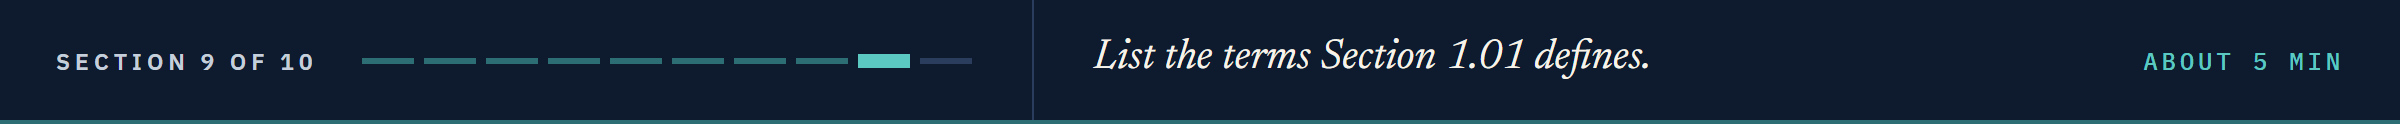

# Defined Terms

## Section 1.01

Each definition in Section 1.01 starts its own line with the term in quotation marks, and its capital letters mark it as a **defined term**.

In [42]:
# Section 1.01: its words, and the lines that start with a quotation mark
definitions = sections.set_index("number").loc["1.01"]
definitions_text = boyd[definitions["start"]:definitions["end"]]
quoted_lines = [line for line in definitions_text.split("\n") if line.startswith('"')]
print(definitions["words"], "words |", len(quoted_lines), "lines start with a quoted term")

16910 words | 148 lines start with a quoted term


**Predict 5**

Q. A pattern reads `"Term" means` and `"Term" has the meaning`. Of the 148 lines, how many does it find? Write down a number.

## A Pattern for `"Term" means`

`{0,100}?` takes at most 100 characters, as few as it can.

In [43]:
# a quoted term that starts with a capital or a digit, then "means" or "has the meaning"
def defined_terms(text):
    """Every "Term" means or "Term" has the meaning in a text: the term, where it starts, and which form."""
    pattern = r'"(?P<term>[A-Z0-9][^"\n]{0,100}?)"\s+(?P<kind>means|has the meaning)\b'
    rows = [{"term": found["term"], "start": found.start(), "kind": found["kind"]} for found in re.finditer(pattern, text)]
    return pd.DataFrame(rows)


# the terms of Section 1.01: how many, how many distinct, and which form each takes
terms = defined_terms(definitions_text)
print(len(terms), "terms |", terms["term"].nunique(), "distinct |", terms["kind"].value_counts().to_dict())

136 terms | 136 distinct | {'means': 132, 'has the meaning': 4}


## The Definition of Indebtedness, and the Twelve It Missed

The lines the pattern misses write a definition another way: "shall mean", "shall be deemed", or other words between the term and "means".

In [44]:
# source text: quoted as published
# the first 500 characters of the definition of Indebtedness
start = terms.loc[terms["term"] == "Indebtedness", "start"].iloc[0]
print(definitions_text[start:start + 500])

# the quoted term of each line the pattern did not find
missed = [re.search(r'"([^"]+)"', line).group(1) for line in quoted_lines]
missed = [term for term in missed if term not in set(terms["term"])]
print(len(missed), missed)
boyd_source("1.01")

"Indebtedness" means (without duplication), with respect to any Person, any indebtedness, secured or unsecured, contingent or otherwise:
(a) which is for borrowed money (whether or not the recourse of the lender is to the whole of the Property of such Person or only to a portion thereof), or the principal amount of such indebtedness;
(b) evidenced by bonds, notes, debentures or similar instruments; or
(c) representing the balance deferred and unpaid of the purchase price of any property (excludi
12 ['Additional Lease', 'Change of Control', 'Consolidated Total Assets', 'Corporate Trust Office of the Trustee', 'Disqualified Stock', 'Investment', 'Net Cash Proceeds', 'Net Proceeds', 'Outstanding', 'Rating Decline', 'Responsible Officer,', 'Subsidiary']
Source: Boyd Gaming Corporation, indenture for the 4.750% Senior Notes due 2031, Exhibit 4.1 to the 8-K filed 2021-06-08, accession 0001193125-21-185495, Section 1.01.


## Consolidated Total Assets in Context

A **keyword in context** view lines up every place a term appears, so its uses read down one column.

Counter({'1.01': 5, '4.12': 2, '1.06': 1, '4.11': 1})


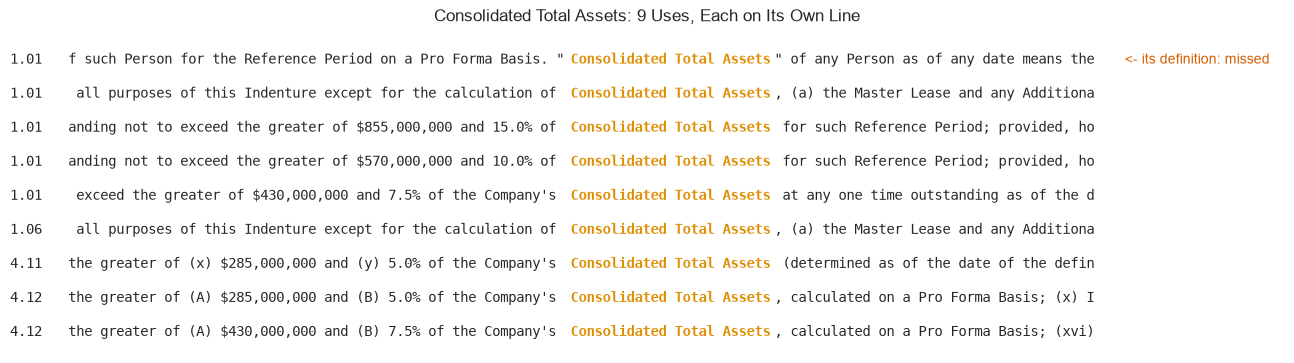

In [45]:
# every place "Consolidated Total Assets" starts, and the section it sits in
TERM = "Consolidated Total Assets"
hits = [found.start() for found in re.finditer(TERM, boyd)]
where = [sections["number"][sections["start"] <= hit].iloc[-1] for hit in hits]
print(Counter(where))

# the 9 uses aligned on the term: its section, 62 characters before it right-aligned, 40 after
# (subplots_adjust stretches the axes across the figure; parse_math=False draws a "$" as itself, not as the start of a formula)
fig, ax = plt.subplots(figsize=(13, 4.2))
fig.subplots_adjust(left=0.01, right=0.99)
for line, (hit, number) in enumerate(zip(hits, where)):
    ax.text(0, -line, number, family="monospace", fontsize=10)
    ax.text(0.435, -line, boyd[hit - 62:hit].replace("\n", " "), family="monospace", fontsize=10, ha="right", parse_math=False)
    ax.text(0.44, -line, TERM, family="monospace", fontsize=10, color="C1", weight="bold")
    ax.text(0.6, -line, boyd[hit + len(TERM):hit + len(TERM) + 40].replace("\n", " "), family="monospace", fontsize=10, parse_math=False)
ax.text(0.875, 0, "<- its definition: missed", color="C3", fontsize=10)
ax.set(xlim=(0, 1), ylim=(-len(hits) + 0.5, 1), title="Consolidated Total Assets: 9 Uses, Each on Its Own Line")
ax.set_axis_off()
plt.show()

Section 1.01 uses the term five times: its own definition, one clause on leases, and three baskets sized as the greater of a fixed amount and a percentage of Consolidated Total Assets.

Section 4.12 uses it twice, Sections 1.06 and 4.11 once each.

Its definition is one `defined_terms` missed; Day 12 widens the pattern before any definition goes into a request to a model.

## Why the Course Keeps Words Whole

**Stemming** cuts a word to a stem, so "restricted" and "restricts" count as one; Course 1's Text Analysis notebook ran the Porter stemmer.
In an indenture a capital letter marks a defined term: "Restricted Subsidiary" is defined, "restricted" in lower case is plain English.

"Restricted": 412 | "Restricted Subsidiar": 250 | "Restricted Payment": 29


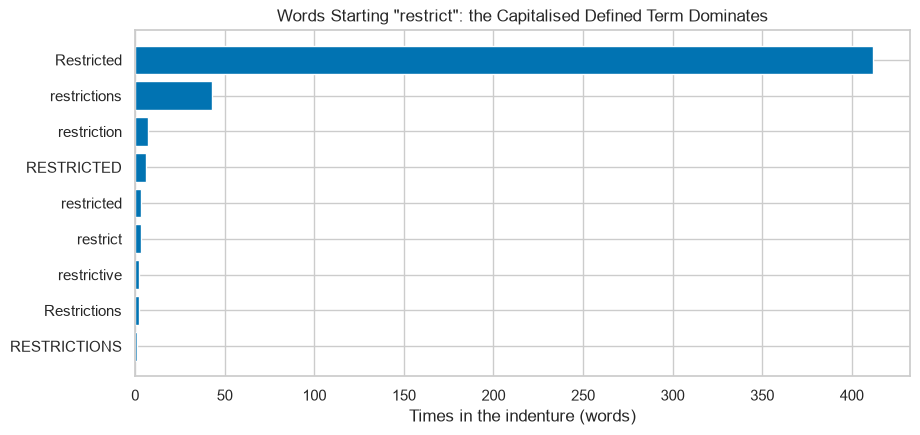

In [46]:
# every word that starts with "restrict", capitals kept, counted in the indenture; then the two defined terms it starts
restrict = Counter(word for word in re.findall(r"[A-Za-z]+", boyd) if word.lower().startswith("restrict"))
restrict = pd.Series(restrict).sort_values()
print('"Restricted":', restrict["Restricted"], '| "Restricted Subsidiar":', boyd.count("Restricted Subsidiar"),
      '| "Restricted Payment":', boyd.count("Restricted Payment"))
plt.figure(figsize=(10, 4.5))
plt.barh(restrict.index, restrict.values)
plt.xlabel("Times in the indenture (words)")
plt.title('Words Starting "restrict": the Capitalised Defined Term Dominates')
plt.show()

"Restricted" with a capital, 412 times, is nearly all of them, most of it in "Restricted Subsidiary" and its plural.

A stemmer would fold the defined term into plain English, so the course keeps words whole and never stems.

**A pattern finds what it was written for; the misses are the definitions written another way.**

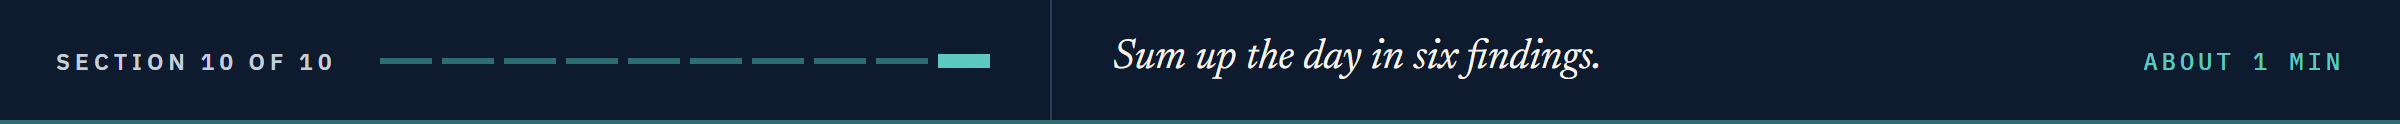

# Insights and Conclusion

Four characters outside ASCII sit in 56 statements, and NFC with one map makes them plain.

222 statements state a rate as a number: 12 only after normalising, 2 only in the Desk's wording.

86,576 tokens, 37.8 percent of them stop words, from a list that holds "interest" and "not".

Statement length is described by date: a median of 178 tokens in 2000, 822.5 in 2014, 232 in 2026.

The Boyd indenture has 107 sections, 20 of them covenants in Article 4, each found by its last heading.

`defined_terms` finds 136 of 148 definitions; the 12 it misses are written another way.

**Same character, same word, same section: decided once in code, and checked against the whole document.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Find characters outside ASCII by code point and name, and make look-alikes plain with one map.
* Pull a stated rate out of every statement with named groups, and turn a written fraction into a number.
* Split text into tokens with one pattern, count them, and test a word against a stop list.
* Find an indenture's sections from its headings, keeping each number's last heading.
* List the terms a section defines, and read the lines a pattern misses.

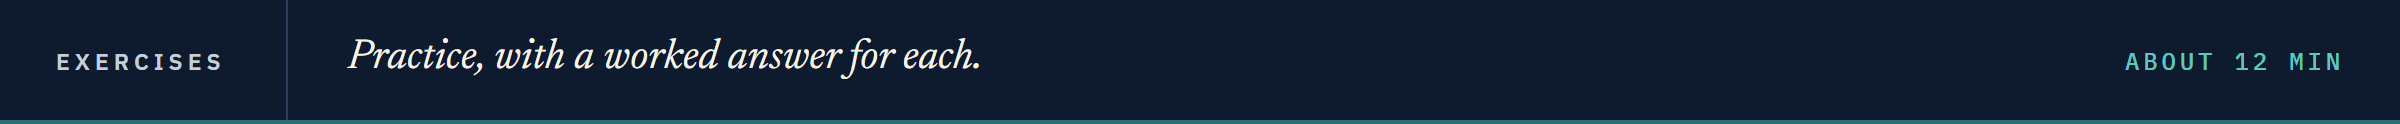

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [47]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Inflation, Year by Year**

Q. Find the share of each year's statements whose tokens include "inflation". Store the year with the lowest share in `ex1_year` (as text, such as "2010") and that share in `ex1_share`.

In [48]:
# your code here
ex1_year = ...
ex1_share = ...

In [49]:
check("Exercise 1 the year with the lowest share", ex1_year, "2002")
check("Exercise 1 the lowest share", ex1_share, 0.125)

Exercise 1 the year with the lowest share: not attempted yet
Exercise 1 the lowest share: not attempted yet


### Exercise 2

**A Function for Sentences**

`re.split(pattern, text)` cuts a text wherever the pattern matches.
In `(?<=[.!?])\s+`, `(?<=...)` looks behind: the white space must follow a full stop, "!" or "?", which stays with its sentence.

Q. Write `sentences(text)`, which normalizes a text and returns its sentences, and store the number of sentences in the first statement in `ex2_first`.

In [50]:
# your code here
ex2_first = ...

In [51]:
check("Exercise 2 the sentences in the first statement", ex2_first, 8)

Exercise 2 the sentences in the first statement: not attempted yet


### Exercise 3

**One Section's Text**

Q. Write `section_text(text, sections, number)`, which returns the text of one section. Store how many times "Indebtedness" appears in Section 4.12 in `ex3_in_412`, and how many of the 107 sections hold it at least once in `ex3_sections`.

In [52]:
# your code here
ex3_in_412 = ...
ex3_sections = ...

In [53]:
check("Exercise 3 Indebtedness in Section 4.12", ex3_in_412, 67)
check("Exercise 3 the sections holding Indebtedness", ex3_sections, 19)

Exercise 3 Indebtedness in Section 4.12: not attempted yet
Exercise 3 the sections holding Indebtedness: not attempted yet


### Exercise 4: AI check

**One Word, Two Spellings**

You asked an AI assistant for a function that splits a statement into lower-case words, with hyphenated words split in two.
This came back.
Test it on every statement, then find the one bug.

In [54]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def statement_words(text):
    """The words of a statement in lower case, hyphenated words split in two."""
    return text.lower().replace("-", " ").split()

In [55]:
# the docstring's promise on every statement: how often "longer" comes back, and the words still holding U+2011
words = [word for text in statements["text"] for word in statement_words(text)]
print('"longer" comes back', words.count("longer"), "times")
print(sum(chr(0x2011) in word for word in words), "words still hold U+2011, such as",
      [word for word in words if chr(0x2011) in word][0].replace(chr(0x2011), "[U+2011]"))

"longer" comes back 393 times
50 words still hold U+2011, such as survey[U+2011]based


Q. Fix the one wrong idea, and store how often "longer" comes back from the fixed function over every statement in `ex4_longer`.

In [56]:
# your code here
ex4_longer = ...

In [57]:
check("Exercise 4 the fixed count of longer", ex4_longer, 400)

Exercise 4 the fixed count of longer: not attempted yet


## Congratulations!

You turned two kinds of desk documents into data you can count and check.
You found four characters that look like keyboard ones and are not, and made them plain with one function.
You read the rate from 222 statements, caught a wording an earlier pattern never looked for, and watched 12 rates vanish without a single error.
You defined a token once, counted 86,576 of them, and mapped a 63,595-word indenture by its 107 sections and its defined terms.
In Day 2 you count the words of every statement and weigh each by how rare it is.

[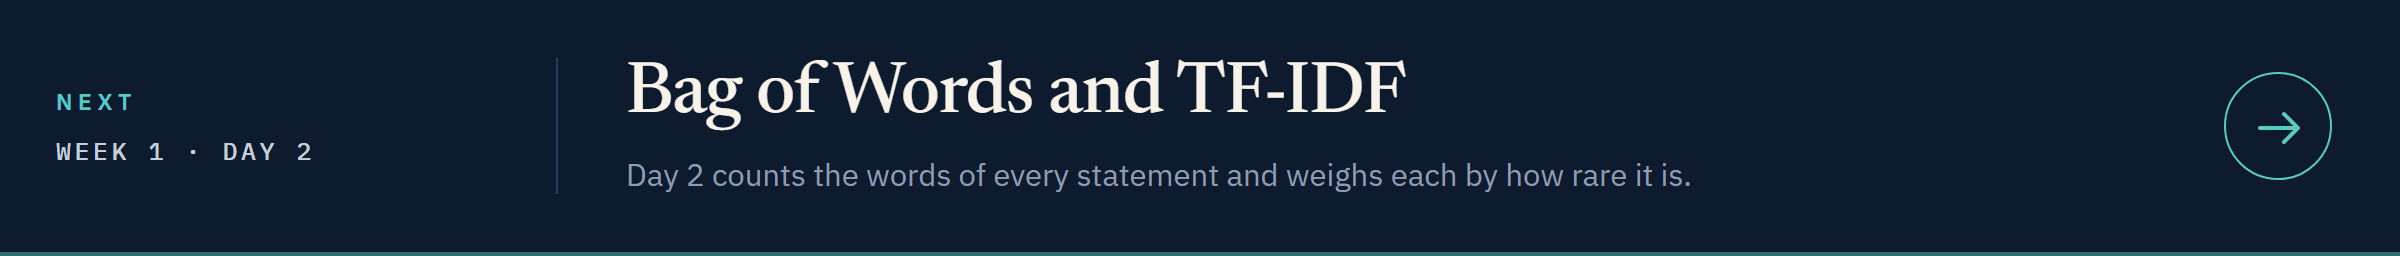](../day2/02_bag_of_words_and_tf_idf.ipynb)

[Open Day 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course07_nlp_and_llms/week1/day2/02_bag_of_words_and_tf_idf.ipynb)